# Collections Compass: early risk model, contact strategy and daily call list

**Project:** Oriel Credit, Collections Compass. **My role:** data scientist. **Deliverables covered:** C1 Model Features, C2 Default Prediction Model, C3 Model Evaluation and Fairness Report, C4 Contact Strategy, and the automated daily call list for the 24 collections agents.

## Contents
- **Step 0:** Set up (import libraries, choose folders)
- **Step 1:** Load the 14 data files
- **Step 2:** Prepare the data for modelling
- **Step 3:** Work out each loan's repayment outcome and define the target
- **Step 4:** Build the leakage-safe features (C1)
- **Step 5:** Split the data by time
- **Step 6:** Train the models (C2)
- **Step 7:** Evaluate the models (C3, performance)
- **Step 8:** Check the model is sound (leakage, time gap, cut-offs)
- **Step 9:** Explain the model with SHAP (C3, explanation)
- **Step 10:** Fairness checks (C3, fairness)
- **Step 11:** Save the models for daily use
- **Step 12:** Agent capacity, and a first look at ranking against alphabetical order
- **Step 13:** Contact history analysis (C4)
- **Step 14:** More contact analysis for the rules (C4)
- **Step 15:** The contact strategy rule table (C4)
- **Step 16:** Compare the new call list with alphabetical order
- **Step 17:** Run the automated daily call list
- **Step 18:** Save the summary numbers

## Step 0: Set up

Load the Python libraries

In [103]:
import os          # file paths and folders
import json        # saving the summary numbers at the end
import warnings    # used to hide harmless warning messages
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display   # shows tables neatly when there is more than one in a cell

print('pandas version:', pd.__version__)

pandas version: 3.1.1


In [104]:
DATA = 'data'
OUT = 'outputs'
FIG = os.path.join(OUT, 'figures')
os.makedirs(FIG, exist_ok=True)      # creates outputs/ and outputs/figures/ if missing

pd.set_option('display.max_columns', 50)   # show up to 50 columns when printing a table
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110           # chart sharpness
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print('Data folder found:', os.path.isdir(DATA))

Data folder found: True


## Step 1: Load the 14 data files

The files were renamed from their long download names to readable names. **Fact** tables hold events (loans, payments, calls, SMS). **Dimension (dim)** tables describe things (customers, agents, dates).

### 1.1 List the files

This dictionary gives each table a short name (on the left) and its file name (on the right).

In [105]:
files = {
    'loans': 'fact_loans.csv',                          # one row per loan: disbursement, principal, due date
    'loan_status': 'dim_loan_status.csv',               # one row per loan: status, term, closed date, loan number
    'payments': 'fact_payments.csv',                    # one row per payment attempt (success or failed)
    'processor': 'fact_processor_transactions.csv',     # the payment processor's copy of the attempts
    'snap_1118': 'fact_loan_balance_snapshot_2026_11_18.csv',
    'snap_1122': 'fact_loan_balance_snapshot_2026_11_22.csv',
    'bureau': 'fact_bureau_pulls.csv',                  # credit bureau checks
    'app_events': 'fact_app_events.csv',                # app activity
    'sms': 'fact_sms_log.csv',                          # reminder and overdue SMS
    'nudges': 'fact_nudges.csv',                        # email, push and WhatsApp nudges
    'calls': 'fact_collection_calls.csv',               # collection calls with outcome and promise to pay
    'customer': 'dim_customer.csv',
    'agent': 'dim_agent.csv',
    'date': 'dim_date.csv',
}
print(len(files), 'files listed')

14 files listed


### 1.2 Read each file

`t` is a dictionary of tables, so `t['loans']` is the loans table.

In [106]:
t = {}
for name, file_name in files.items():
    path = os.path.join(DATA, file_name)
    t[name] = pd.read_csv(path, low_memory=False)   # low_memory=False avoids mixed-type warnings
    print(f'{name:12s} {len(t[name]):>7,} rows  {t[name].shape[1]:>3} columns')

loans         41,815 rows    9 columns
loan_status   42,000 rows    9 columns
payments      45,909 rows   11 columns
processor     46,229 rows   10 columns
snap_1118     42,815 rows    8 columns
snap_1122     41,815 rows    8 columns
bureau        35,652 rows   10 columns
app_events    77,228 rows    7 columns
sms           88,665 rows    8 columns
nudges         2,548 rows    7 columns
calls         19,691 rows    8 columns
customer      18,360 rows   13 columns
agent             24 rows    6 columns
date             457 rows   19 columns


In [107]:
t['loans'].head()

,LOAN_ID,CUSTOMER_ID,DAYS_PAST_DUE,DISBURSEMENT_DATE,PRINCIPAL_AMOUNT_GBP,TOTAL_REPAYABLE_GBP,Loan Size Band,Aging Classification,DUE_DATE
0,L1000199,C102857,NaN,2025-10-06 00:00:00.000,290,333.5,Small Loan,Current,2025-11-05 00:00:00.000
1,L1000231,C117815,NaN,2025-10-06 00:00:00.000,290,333.5,Small Loan,Current,2025-11-05 00:00:00.000
2,L1000536,C112963,NaN,2025-10-14 00:00:00.000,290,333.5,Small Loan,Current,2025-11-13 00:00:00.000
3,L1000746,C112388,NaN,2025-10-19 00:00:00.000,290,333.5,Small Loan,Current,2025-11-18 00:00:00.000
4,L1000770,C105618,NaN,2025-10-20 00:00:00.000,290,333.5,Small Loan,Current,2025-11-19 00:00:00.000


## Step 2: Prepare the data for modelling

The raw files have a few known problems. We fix or work around each one, one sub-step at a time.

Below is a list of problems and possible solutions

| # | Problem | What we do |
|---|---|---|
| 2.1 | 185 loans exist only in `dim_loan_status` | Keep only loans in `fact_loans` |
| 2.2 | Payment times are in UTC; everything else is UK local time | Convert payments to UK time |
| 2.3 | Failed payments still show the full amount in `AMOUNT_PAID_GBP` | Count money only on `Success` rows |
| 2.4 | App event times are Excel times dated 30 December 1899 | Add the time onto the event date |
| 2.5 | App event names have two spellings (`AppOpen` and `app_open`) | Map to one spelling |
| 2.6 | Dates are stored as text | Convert to real dates |
| 2.7 | 54 calls have a duration of -1 seconds | Set to blank |
| 2.8 | 261 bureau pulls have a credit score of 0 | Treat as blank |
| 2.9 | Some SMS, calls and nudges point to unknown loans | Drop those rows |
| 2.10 | Data ends on 4 November 2026 | Set the cut-off date |

**Why `Days Overdue` is never used:** in `dim_loan_status` it is simply the number of days from the due date to the date the file was extracted (even loans repaid on their due date show 18 to 403 days), so it measures the loan's age rather than lateness and would leak the future into the model.

### 2.1 Combine the two loan tables

`fact_loans` has the amounts and dates; `dim_loan_status` has the term, status and the customer's loan number. A left join keeps only the 41,815 loans in `fact_loans`, which drops the 185 status-only loans.

In [108]:
status_cols = ['LOAN_ID', 'CLOSED_DATE', 'TERM_DAYS', 'LOAN_STATUS', 'REPAYMENT_METHOD', 'CUSTOMER_LOAN_NUMBER']
loans = t['loans'].merge(t['loan_status'][status_cols], on='LOAN_ID', how='left')
loans['DISBURSEMENT_DATE'] = pd.to_datetime(loans['DISBURSEMENT_DATE'])
loans['DUE_DATE'] = pd.to_datetime(loans['DUE_DATE'])
loans['CLOSED_DATE'] = pd.to_datetime(loans['CLOSED_DATE'])
# check: the due date should always be disbursement date + term
term_matches = (loans['DUE_DATE'] - loans['DISBURSEMENT_DATE']).dt.days == loans['TERM_DAYS']
print('Loans:', len(loans), '| due date = disbursement + term for all loans:', term_matches.all())

Loans: 41815 | due date = disbursement + term for all loans: True


### 2.2 Convert payment times from UTC to UK time

In [109]:
pay = t['payments'].copy()
utc_times = pd.to_datetime(pay['PAYMENT_DATETIME_UTC']).dt.tz_localize('UTC')
pay['ts'] = utc_times.dt.tz_convert('Europe/London').dt.tz_localize(None)
pay[['PAYMENT_DATETIME_UTC', 'ts']].head()

,PAYMENT_DATETIME_UTC,ts
0,2025-11-01 06:07:19.000,2025-11-01 06:07:19
1,2025-11-01 06:11:17.000,2025-11-01 06:11:17
2,2025-11-03 06:08:39.000,2025-11-03 06:08:39
3,2025-11-03 06:02:12.000,2025-11-03 06:02:12
4,2025-12-05 06:07:15.000,2025-12-05 06:07:15


### 2.3 Count money only on successful payments

Failed rows show the full amount in `AMOUNT_PAID_GBP` even though no money arrived. We create `paid_gbp`, which is 0 for failed rows.

In [110]:
failed_with_amount = (pay['PAYMENT_STATUS'] == 'Failed') & (pay['AMOUNT_PAID_GBP'] > 0)
print('Failed rows that still show an amount paid:', int(failed_with_amount.sum()))
pay['paid_gbp'] = np.where(pay['PAYMENT_STATUS'] == 'Success', pay['AMOUNT_PAID_GBP'], 0.0)

Failed rows that still show an amount paid: 6445


### 2.4 Fix the app event times

`Event_Time_Local` holds only a time of day, stored as a date in 1899 (an Excel habit). We take the time part and add it to `Event_Date_Local`.

In [111]:
ev = t['app_events'].copy()
event_date = pd.to_datetime(ev['Event_Date_Local'])
time_of_day = pd.to_datetime(ev['Event_Time_Local']) - pd.Timestamp('1899-12-30')   # time since midnight
ev['ts'] = event_date + time_of_day
ev[['Event_Date_Local', 'Event_Time_Local', 'ts']].head(5)

,Event_Date_Local,Event_Time_Local,ts
0,2026-09-02 00:00:00.000,1899-12-30 07:06:19.000,2026-09-02 07:06:19
1,2026-09-02 00:00:00.000,1899-12-30 07:07:37.000,2026-09-02 07:07:37
2,2026-09-02 00:00:00.000,1899-12-30 07:17:58.000,2026-09-02 07:17:58
3,2026-09-02 00:00:00.000,1899-12-30 07:18:23.000,2026-09-02 07:18:23
4,2026-09-02 00:00:00.000,1899-12-30 07:22:25.000,2026-09-02 07:22:25


### 2.5 Use one spelling for each app event name

Two app versions log the same event with different names. We map the CamelCase names to the snake_case names.

In [112]:
name_map = {
    'AppOpen': 'app_open', 'ViewRepayment': 'view_repayment_screen', 'SmsLinkClick': 'sms_link_click',
    'TapPayNow': 'tap_pay_now', 'PaymentConfirmed': 'payment_confirmed', 'NotificationOpened': 'notification_opened',
    'PaymentError': 'payment_error_shown', 'DebitFailedNotifOpened': 'debit_failed_notification_opened'}
ev['event'] = ev['EVENT_NAME'].replace(name_map)
print(ev['event'].value_counts())

event
app_open                            30432
view_repayment_screen               13493
sms_link_click                      11009
tap_pay_now                         10781
payment_confirmed                   10531
notification_opened                   403
payment_error_shown                   329
debit_failed_notification_opened      250
Name: count, dtype: int64


### 2.6 Convert the other date columns

SMS, nudges, calls, bureau pulls and customers have dates stored as text. We convert them so we can compare times.

In [113]:
sms = t['sms'].copy()
sms['ts'] = pd.to_datetime(sms['SEND_DATETIME_LOCAL'])
nud = t['nudges'].copy()
nud['ts'] = pd.to_datetime(nud['SENT_DATETIME_LOCAL'])
calls = t['calls'].copy()
calls['ts'] = pd.to_datetime(calls['CALL_DATETIME_LOCAL'])
calls['PROMISE_TO_PAY_DATE'] = pd.to_datetime(calls['PROMISE_TO_PAY_DATE'])
bureau = t['bureau'].copy()
bureau['PULL_DATE'] = pd.to_datetime(bureau['PULL_DATE'])
cust = t['customer'].copy()
cust['SIGNUP_DATE'] = pd.to_datetime(cust['SIGNUP_DATE'])
print('Dates converted')

Dates converted


### 2.7 Blank out negative call durations

A call cannot last -1 seconds, so these values are errors.

In [114]:
print('Calls with negative duration:', int((calls['CALL_DURATION_SEC'] < 0).sum()))
calls.loc[calls['CALL_DURATION_SEC'] < 0, 'CALL_DURATION_SEC'] = np.nan

Calls with negative duration: 54


### 2.8 Treat a credit score of 0 as missing

All 261 zero scores are on files marked `Scored`, so 0 looks like a placeholder rather than a real score.

In [115]:
print('Credit score of 0:', int((bureau['CREDIT_SCORE'] == 0).sum()))
bureau.loc[bureau['CREDIT_SCORE'] == 0, 'CREDIT_SCORE'] = np.nan

Credit score of 0: 261


### 2.9 Drop rows that point to unknown loans

Rows whose `LOAN_ID` is not in `loans` cannot be linked to a loan outcome. App events with a blank `LOAN_ID` are kept, because they still belong to a customer.

In [116]:
known = loans['LOAN_ID']
print('SMS rows dropped:', int((~sms['LOAN_ID'].isin(known)).sum()))
print('Nudge rows dropped:', int((~nud['LOAN_ID'].isin(known)).sum()))
print('Call rows dropped:', int((~calls['LOAN_ID'].isin(known)).sum()))
sms = sms[sms['LOAN_ID'].isin(known)].copy()
nud = nud[nud['LOAN_ID'].isin(known)].copy()
calls = calls[calls['LOAN_ID'].isin(known)].copy()
ev = ev[ev['LOAN_ID'].isna() | ev['LOAN_ID'].isin(known)].copy()

SMS rows dropped: 406
Nudge rows dropped: 10
Call rows dropped: 109


### 2.10 Set the data cut-off

All event tables stop on 4 November 2026, so outcomes after that date are unknown.

In [117]:
DATA_CUTOFF = pd.Timestamp('2026-11-04')
print('Latest payment (UK time):', pay['ts'].max())
print('Data cut-off used:', DATA_CUTOFF.date())

Latest payment (UK time): 2026-11-04 21:39:45
Data cut-off used: 2026-11-04


## Step 3: Work out each loan's repayment outcome and define the target

The model needs a clear yes or no **target**. We rebuilt each loan's repayment from successful payments, the moment the running total paid reaches the total repayable is the moment the loan was **fully repaid**.

**Proposed target: `default_30` = the loan is still not fully repaid 30 days after its due date.**

### 3.1 Add up successful payments over time for each loan

We sort payments by time and keep a running total per loan (`cum_paid`).

In [118]:
p = pay.merge(loans[['LOAN_ID', 'TOTAL_REPAYABLE_GBP', 'DUE_DATE']], on='LOAN_ID')
p = p.sort_values('ts')
p['cum_paid'] = p.groupby('LOAN_ID')['paid_gbp'].cumsum()   # running total of money received
p[['LOAN_ID', 'ts', 'PAYMENT_STATUS', 'paid_gbp', 'cum_paid', 'TOTAL_REPAYABLE_GBP']].head()

,LOAN_ID,ts,PAYMENT_STATUS,paid_gbp,cum_paid,TOTAL_REPAYABLE_GBP
32448,L1000173,2025-10-14 10:28:24,Success,113.87,113.87,278.2
20508,L1000077,2025-10-14 12:50:04,Success,267.50,267.50,267.5
32450,L1000017,2025-10-14 16:16:13,Success,1037.90,1037.90,1037.9
6985,L1000032,2025-10-15 07:09:40,Success,460.10,460.10,460.1
32449,L1000173,2025-10-15 08:28:24,Success,164.33,278.20,278.2


### 3.2 Find the moment each loan was fully repaid

The first payment where the running total reaches the amount owed (allowing 1p for rounding) is the full-repayment moment. `days_to_full` is the number of days from the due date to that moment; negative means early.

In [119]:
reached = p[p['cum_paid'] >= p['TOTAL_REPAYABLE_GBP'] - 0.01]
full_ts = reached.groupby('LOAN_ID')['ts'].min().rename('FULLY_REPAID_TS')
loans = loans.merge(full_ts, on='LOAN_ID', how='left')
loans['days_to_full'] = (loans['FULLY_REPAID_TS'].dt.normalize() - loans['DUE_DATE']).dt.days
print('Loans fully repaid:', int(loans['FULLY_REPAID_TS'].notna().sum()), 'of', len(loans))

Loans fully repaid: 38064 of 41815


### 3.3 Check our rebuild against the snapshot and the loan status

If the rebuild is right, total paid should match the 22 November snapshot, and every `Repaid` loan should be fully repaid.

In [120]:
s22 = t['snap_1122']                                          # the 22 November balance snapshot
total_paid = p.groupby('LOAN_ID')['paid_gbp'].sum()
check = s22.set_index('LOAN_ID')[['TOTAL_COLLECTED']].fillna(0)
check['rebuilt_paid'] = total_paid.reindex(check.index).fillna(0)
print('Loans where totals differ:', int(((check['rebuilt_paid'] - check['TOTAL_COLLECTED']).abs() > 0.01).sum()))
pd.crosstab(loans['LOAN_STATUS'], loans['FULLY_REPAID_TS'].notna(), colnames=['fully repaid by rebuild'])

Loans where totals differ: 0


fully repaid by rebuild,False,True
LOAN_STATUS,,
Active,1028,0
Overdue,1224,0
Repaid,0,38064
Written off,1499,0


### 3.4 Add the outcome flags

`on_time` = fully repaid by the end of the due date. `default_30` = not fully repaid within 30 days of the due date. `outcome_30_known` = the due date is at least 30 days before the cut-off, so we know the answer.

In [121]:
loans['on_time'] = loans['days_to_full'] <= 0
loans['default_30'] = ~(loans['days_to_full'] <= 30)        # never repaid (blank) also counts as default
loans['default_60'] = ~(loans['days_to_full'] <= 60)
loans['outcome_30_known'] = loans['DUE_DATE'] + pd.Timedelta(days=30) <= DATA_CUTOFF
print('Loans with a known 30-day outcome:', int(loans['outcome_30_known'].sum()))

Loans with a known 30-day outcome: 37685


### 3.5 Add customer names for the alphabetical baseline

Names are only used in Step 12 to copy today's alphabetical call order. They are never model inputs.

In [122]:
loans = loans.merge(cust[['CUSTOMER_ID', 'LAST_NAME', 'FIRST_NAME']], on='CUSTOMER_ID', how='left')
print(loans[['LOAN_ID', 'LAST_NAME', 'FIRST_NAME']].head(3))

    LOAN_ID LAST_NAME FIRST_NAME
0  L1000199     Allen      Bilal
1  L1000231    Bryant      Grace
2  L1000536   Francis      Katie


### 3.6 Define the scored population and the base rate

The main model scores loans on the **morning after the due date (day 1)**, and only loans **not fully repaid by the end of the due date**. These are exactly the accounts that enter collections. The **base rate** is the share of them that default.

In [123]:
pop = loans[(~loans['on_time']) & loans['outcome_30_known']].copy()
all_known = loans[loans['outcome_30_known']]
print(f'Scored population (missed the due date, outcome known): {len(pop):,}')
print(f'default_30 base rate in scored population: {pop["default_30"].mean():.1%} ({int(pop["default_30"].sum()):,} loans)')
print(f'default_30 rate across all loans with a known outcome: {all_known["default_30"].mean():.1%}')

Scored population (missed the due date, outcome known): 6,030
default_30 base rate in scored population: 39.3% (2,367 loans)
default_30 rate across all loans with a known outcome: 6.3%


## Step 4: Build the leakage-safe features (C1)

Every feature must be known **before the scoring point**. Anything recorded later (overdue SMS, calls, nudges, later payments, snapshot aging) would make the model look better in testing than it can ever be in real use. That is called **data leakage**. Every time filter below keeps only records with `timestamp < score_ts`.

We build the same features for **two scoring points**:
- **Model B, collections (main model):** 00:00 on day 1 after the due date, for loans that missed full repayment. It ranks the daily call list.
- **Model A, early warning:** 00:00 on the due date, for every loan not yet fully repaid. It shows who to nudge before or on the due date.

**Kept out of both models on purpose:** age and region (used only for the fairness checks in Step 10), and customer names (used only for the alphabetical baseline in Step 12).

We write one small function per feature group (4.1 to 4.9), then call them all in 4.10.

In [124]:
def start_table(base, score_lag_days):
    base = base.reset_index(drop=True)
    keep = ['LOAN_ID', 'CUSTOMER_ID', 'DISBURSEMENT_DATE', 'DUE_DATE', 'default_30', 'LAST_NAME', 'FIRST_NAME', 'LOAN_STATUS', 'FULLY_REPAID_TS']
    F = base[keep].copy()
    F['score_ts'] = F['DUE_DATE'] + pd.Timedelta(days=score_lag_days)   # 0 = start of due date, 1 = start of day 1
    return F, base
print('start_table ready')

start_table ready


### 4.2 Loan terms


In [125]:
def add_loan_terms(F, base):
    F['principal_gbp'] = base['PRINCIPAL_AMOUNT_GBP']
    F['total_repayable_gbp'] = base['TOTAL_REPAYABLE_GBP']
    F['cost_of_credit_pct'] = (base['TOTAL_REPAYABLE_GBP'] / base['PRINCIPAL_AMOUNT_GBP'] - 1) * 100
    F['term_days'] = base['TERM_DAYS']
    F['repayment_method'] = base['REPAYMENT_METHOD']
    F['customer_loan_number'] = base['CUSTOMER_LOAN_NUMBER']
    F['due_day_of_week'] = F['DUE_DATE'].dt.dayofweek                 # 0 = Monday, 6 = Sunday
    F['due_on_weekend'] = (F['due_day_of_week'] >= 5).astype(int)
    F['due_day_of_month'] = F['DUE_DATE'].dt.day
    return F
print('add_loan_terms ready')

add_loan_terms ready


### 4.3 Payment behaviour before scoring

Payment attempts and failures before the scoring time, the reason for the last failure, and how much was part-paid. For Model B this includes everything that happened on the due date. `balance_at_scoring` is kept for ranking the call list. It is not a model feature.

In [126]:
def add_payment_features(F):
    pp = pay.merge(F[['LOAN_ID', 'score_ts']], on='LOAN_ID')
    pp = pp[pp['ts'] < pp['score_ts']].sort_values('ts')        # only attempts before scoring
    failed = pp[pp['PAYMENT_STATUS'] == 'Failed']
    paid = pp.groupby('LOAN_ID')['paid_gbp'].sum()
    F['n_payment_attempts_before_scoring'] = F['LOAN_ID'].map(pp.groupby('LOAN_ID').size()).fillna(0)
    F['n_failed_attempts_before_scoring'] = F['LOAN_ID'].map(failed.groupby('LOAN_ID').size()).fillna(0)
    F['last_failure_reason'] = F['LOAN_ID'].map(failed.groupby('LOAN_ID')['FAILURE_REASON'].last()).fillna('No failed attempt')
    paid_so_far = F['LOAN_ID'].map(paid).fillna(0)
    F['share_paid_before_scoring'] = paid_so_far / F['total_repayable_gbp']
    F['balance_at_scoring'] = (F['total_repayable_gbp'] - paid_so_far).round(2)
    return F
print('add_payment_features ready')

add_payment_features ready


### 4.4 Repayment history on earlier loans

For each loan we look at the same customer's other loans whose due date had already passed at scoring. We count how many were late, how many defaulted (only where that was already known), and how many were still unpaid.

In [127]:
def add_prior_loan_features(F):
    hist = loans[['LOAN_ID', 'CUSTOMER_ID', 'DUE_DATE', 'FULLY_REPAID_TS']]
    pr = F[['LOAN_ID', 'CUSTOMER_ID', 'score_ts']].merge(hist, on='CUSTOMER_ID', suffixes=('', '_prior'))
    is_other_loan = pr['LOAN_ID_prior'] != pr['LOAN_ID']
    already_due = pr['DUE_DATE'] + pd.Timedelta(days=1) <= pr['score_ts']      # its due date had fully passed
    pr = pr[is_other_loan & already_due].copy()
    pr['late'] = ~(pr['FULLY_REPAID_TS'] < pr['DUE_DATE'] + pd.Timedelta(days=1))
    outcome_known = pr['DUE_DATE'] + pd.Timedelta(days=31) <= pr['score_ts']
    pr['def30'] = outcome_known & ~(pr['FULLY_REPAID_TS'] < pr['DUE_DATE'] + pd.Timedelta(days=31))
    pr['open_overdue'] = ~(pr['FULLY_REPAID_TS'] < pr['score_ts'])
    g = pr.groupby('LOAN_ID')
    F['prior_loans_due'] = F['LOAN_ID'].map(g.size()).fillna(0)
    F['prior_late_count'] = F['LOAN_ID'].map(g['late'].sum()).fillna(0)
    F['prior_late_rate'] = F['prior_late_count'] / F['prior_loans_due'].replace(0, np.nan)   # blank if no earlier loans
    F['prior_default30_count'] = F['LOAN_ID'].map(g['def30'].sum()).fillna(0)
    F['prior_open_overdue_loans'] = F['LOAN_ID'].map(g['open_overdue'].sum()).fillna(0)
    return F
print('add_prior_loan_features ready')

add_prior_loan_features ready


### 4.5 Earlier collection calls

Calls to the same customer before scoring, and how many ended in a promise to pay, a refusal or a wrong number.

In [128]:
def add_call_history(F):
    pc = calls.merge(F[['LOAN_ID', 'CUSTOMER_ID', 'score_ts']], on='CUSTOMER_ID', suffixes=('_call', ''))
    pc = pc[pc['ts'] < pc['score_ts']]
    F['prior_calls'] = F['LOAN_ID'].map(pc.groupby('LOAN_ID').size()).fillna(0)
    outcomes = {'Spoke - promise to pay': 'prior_promises_to_pay', 'Spoke - refused to pay': 'prior_refusals', 'Wrong number': 'prior_wrong_number_calls'}
    for outcome, col in outcomes.items():
        F[col] = F['LOAN_ID'].map(pc[pc['CALL_OUTCOME'] == outcome].groupby('LOAN_ID').size()).fillna(0)
    return F
print('add_call_history ready')

add_call_history ready


### 4.6 Credit bureau data

Take the customer's latest bureau pull **on or before the disbursement date**

In [129]:
def add_bureau_features(F):
    left = F[['LOAN_ID', 'CUSTOMER_ID', 'DISBURSEMENT_DATE']].sort_values('DISBURSEMENT_DATE')
    right = bureau.sort_values('PULL_DATE')
    x = pd.merge_asof(left, right, left_on='DISBURSEMENT_DATE', right_on='PULL_DATE', by='CUSTOMER_ID', direction='backward')
    x = x.set_index('LOAN_ID')
    F['bureau_available'] = F['LOAN_ID'].map(x['PULL_DATE'].notna().astype(int))
    F['bureau_thin_file'] = F['LOAN_ID'].map((x['FILE_STATUS'] == 'Thin file').astype(float)).where(F['bureau_available'] == 1)
    columns = {'CREDIT_SCORE': 'credit_score', 'CCJ_FLAG': 'ccj_flag', 'ENQUIRIES_6M': 'enquiries_6m',
               'MISSED_PAYMENTS_12M': 'missed_payments_12m', 'ACTIVE_CREDIT_ACCOUNTS': 'active_credit_accounts',
               'TOTAL_UNSECURED_DEBT_GBP': 'unsecured_debt_gbp'}
    for source, col in columns.items():
        F[col] = F['LOAN_ID'].map(x[source])
    F['days_since_bureau_pull'] = F['LOAN_ID'].map((x['DISBURSEMENT_DATE'] - x['PULL_DATE']).dt.days)
    return F
print('add_bureau_features ready')

add_bureau_features ready


### 4.7 Customer details, payday timing, and the fairness-only columns

Employment, income band, channel, device, SMS opt-in, valid phone and time as a customer are model features. `days_since_payday_at_due` counts days from the last payday to the due date **Age band and region are added for fairness checks only.**

In [130]:
def days_since_payday(due, payday_dom):
    # days from the most recent payday (on or before the due date) to the due date; payday 31 means the last day of the month
    if pd.isna(payday_dom):
        return np.nan
    def payday_in(month_start):
        last_day = (month_start + pd.offsets.MonthEnd(0)).day
        return month_start + pd.Timedelta(days=min(int(payday_dom), last_day) - 1)
    candidate = payday_in(due.replace(day=1))
    if candidate > due:                                         # this month's payday is after the due date, so use last month's
        previous_month = (due.replace(day=1) - pd.Timedelta(days=1)).replace(day=1)
        candidate = payday_in(previous_month)
    return (due - candidate).days

def add_customer_features(F):
    c = cust.set_index('CUSTOMER_ID')
    F['employment_status'] = F['CUSTOMER_ID'].map(c['EMPLOYMENT_STATUS']).fillna('Unknown')
    F['income_band'] = F['CUSTOMER_ID'].map(c['MONTHLY_INCOME_BAND']).fillna('Unknown')
    F['acquisition_channel'] = F['CUSTOMER_ID'].map(c['ACQUISITION_CHANNEL'])
    F['device_os'] = F['CUSTOMER_ID'].map(c['DEVICE_OS'])
    F['sms_opt_in'] = (F['CUSTOMER_ID'].map(c['SMS_OPT_IN']) == 'Y').astype(int)
    F['phone_valid'] = (F['CUSTOMER_ID'].map(c['PHONE_VALID']) == 'Y').astype(int)
    F['tenure_days_at_disbursement'] = (F['DISBURSEMENT_DATE'] - F['CUSTOMER_ID'].map(c['SIGNUP_DATE'])).dt.days
    payday = F['CUSTOMER_ID'].map(c['PAYDAY_DAY_OF_MONTH'])
    F['payday_known'] = payday.notna().astype(int)
    F['days_since_payday_at_due'] = [days_since_payday(d, pdom) for d, pdom in zip(F['DUE_DATE'], payday)]
    # fairness-only columns (NOT model features)
    F['age_at_due'] = F['DUE_DATE'].dt.year - F['CUSTOMER_ID'].map(c['YEAR_OF_BIRTH'])
    F['age_band'] = pd.cut(F['age_at_due'], [0, 24, 34, 44, 120], labels=['18-24', '25-34', '35-44', '45+']).astype(str)
    F['region'] = F['CUSTOMER_ID'].map(c['REGION'])
    return F
print('Example: due 5 Oct 2026, payday on the 25th ->', days_since_payday(pd.Timestamp('2026-10-05'), 25), 'days since payday')

Example: due 5 Oct 2026, payday on the 25th -> 10 days since payday


### 4.8 Reminder SMS sent before scoring

In the SMS log the pre-due reminder goes out at 17:00 the day before the due date, and the due-day reminder at 08:00 on the due date. For Model A (scored at 00:00 on the due date) the due-day SMS has not been sent yet, so it is always 0. Overdue notices (09:00 on day 1 and day 3) are after both scoring points and are never used as features.

In [131]:
def add_sms_features(F):
    s = sms.merge(F[['LOAN_ID', 'score_ts']], on='LOAN_ID')
    s = s[s['ts'] < s['score_ts']]
    def delivered(message_type):
        rows = s[s['MESSAGE_TYPE'] == message_type]
        return rows.groupby('LOAN_ID')['DELIVERY_STATUS'].apply(lambda v: int((v == 'DELIVERED').any()))
    F['pre_due_sms_delivered'] = F['LOAN_ID'].map(delivered('PRE_DUE_REMINDER')).fillna(0)
    F['due_day_sms_delivered'] = F['LOAN_ID'].map(delivered('DUE_DAY_REMINDER')).fillna(0)
    F['sms_failed_before_scoring'] = F['LOAN_ID'].map(s[s['DELIVERY_STATUS'] == 'FAILED'].groupby('LOAN_ID').size()).fillna(0)
    invalid = s[s['FAILURE_CODE'] == 'INVALID_NUMBER'].groupby('LOAN_ID').size()
    F['sms_invalid_number'] = F['LOAN_ID'].map(invalid).fillna(0).clip(upper=1)    # 1 if any SMS failed as an invalid number
    return F
print('add_sms_features ready')

add_sms_features ready


### 4.9 App activity in the 14 days before scoring

Counts of app opens, repayment screen views, pay-now taps, payment errors and similar events by this customer in the 14 days up to scoring.

In [132]:
def add_app_features(F):
    a = ev.merge(F[['LOAN_ID', 'CUSTOMER_ID', 'score_ts']], on='CUSTOMER_ID', suffixes=('_ev', ''))
    in_window = (a['ts'] < a['score_ts']) & (a['ts'] >= a['score_ts'] - pd.Timedelta(days=14))
    a = a[in_window]
    events = {'app_open': 'app_opens_14d', 'view_repayment_screen': 'repayment_screen_views_14d', 'tap_pay_now': 'tap_pay_now_14d',
              'payment_error_shown': 'payment_errors_14d', 'sms_link_click': 'sms_link_clicks_14d',
              'debit_failed_notification_opened': 'debit_failed_notif_opened_14d'}
    for event_name, col in events.items():
        F[col] = F['LOAN_ID'].map(a[a['event'] == event_name].groupby('LOAN_ID').size()).fillna(0)
    F['app_events_14d'] = F['LOAN_ID'].map(a.groupby('LOAN_ID').size()).fillna(0)
    return F
print('add_app_features ready')

add_app_features ready


### 4.10 Build the two model tables

We run all the functions above for each scoring point. Model B uses the population from 3.6. Model A uses every loan with a known outcome that was not fully repaid before 00:00 on its due date.

In [133]:
def build_features(base, score_lag_days):
    F, base = start_table(base, score_lag_days)
    F = add_loan_terms(F, base)
    F = add_payment_features(F)
    F = add_prior_loan_features(F)
    F = add_call_history(F)
    F = add_bureau_features(F)
    F = add_customer_features(F)
    F = add_sms_features(F)
    F = add_app_features(F)
    return F

F = build_features(pop, score_lag_days=1)                                    # Model B
pre_pop = loans[loans['outcome_30_known'] & ~(loans['FULLY_REPAID_TS'] < loans['DUE_DATE'])]
FA = build_features(pre_pop, score_lag_days=0)                               # Model A
print(f'Model B (day 1):    {len(F):,} loans, default rate {F["default_30"].mean():.1%}')
print(f'Model A (due date): {len(FA):,} loans, default rate {FA["default_30"].mean():.1%}')

Model B (day 1):    6,030 loans, default rate 39.3%
Model A (due date): 28,938 loans, default rate 8.2%


### 4.11 List the model features

`NUM` holds number features and `CAT` holds category features. Age band, region, names and `balance_at_scoring` are deliberately not in these lists.

In [134]:
NUM = ['principal_gbp', 'total_repayable_gbp', 'cost_of_credit_pct', 'term_days', 'customer_loan_number',
       'due_day_of_week', 'due_on_weekend', 'due_day_of_month',
       'n_payment_attempts_before_scoring', 'n_failed_attempts_before_scoring', 'share_paid_before_scoring',
       'prior_loans_due', 'prior_late_count', 'prior_late_rate', 'prior_default30_count', 'prior_open_overdue_loans',
       'prior_calls', 'prior_promises_to_pay', 'prior_refusals', 'prior_wrong_number_calls',
       'bureau_available', 'bureau_thin_file', 'credit_score', 'ccj_flag', 'enquiries_6m', 'missed_payments_12m',
       'active_credit_accounts', 'unsecured_debt_gbp', 'days_since_bureau_pull',
       'sms_opt_in', 'phone_valid', 'tenure_days_at_disbursement', 'payday_known', 'days_since_payday_at_due',
       'pre_due_sms_delivered', 'due_day_sms_delivered', 'sms_failed_before_scoring', 'sms_invalid_number',
       'app_opens_14d', 'repayment_screen_views_14d', 'tap_pay_now_14d', 'payment_errors_14d',
       'sms_link_clicks_14d', 'debit_failed_notif_opened_14d', 'app_events_14d']
CAT = ['repayment_method', 'last_failure_reason', 'employment_status', 'income_band', 'acquisition_channel', 'device_os']
FEATURES = NUM + CAT
FAIRNESS_ONLY = ['age_band', 'region']
print(len(NUM), 'number features +', len(CAT), 'category features =', len(FEATURES))

45 number features + 6 category features = 51


### 4.12 Write the features dictionary

For each feature we record its definition, source table and column, why it is included, and when it becomes available. This is C1 deliverable

In [135]:
def make_row(feature, definition, source, reason, available):
    return {'feature': feature, 'definition': definition, 'source': source, 'reason': reason, 'available_at_scoring': available}

dictionary_rows = [
    make_row('principal_gbp', 'Amount lent (GBP)', 'fact_loans.PRINCIPAL_AMOUNT_GBP', 'Larger loans are harder to repay', 'Yes, set at disbursement'),
    make_row('total_repayable_gbp', 'Amount due at the due date (GBP)', 'fact_loans.TOTAL_REPAYABLE_GBP', 'Size of the repayment', 'Yes, set at disbursement'),
    make_row('cost_of_credit_pct', 'Total repayable / principal - 1, as a percentage', 'fact_loans', 'Pricing reflects risk and affordability', 'Yes, set at disbursement'),
    make_row('term_days', 'Loan term in days', 'dim_loan_status.TERM_DAYS', 'Term length affects repayment', 'Yes, set at disbursement'),
    make_row('repayment_method', 'Card auto-debit, in-app card payment or bank transfer', 'dim_loan_status.REPAYMENT_METHOD', 'Manual methods need the customer to act', 'Assumed set at disbursement; confirm with the analyst'),
    make_row('customer_loan_number', '1 = first loan with Oriel, 2 = second, and so on', 'dim_loan_status.CUSTOMER_LOAN_NUMBER', 'Repeat borrowers have a track record', 'Yes'),
    make_row('due_day_of_week', 'Day of week of the due date (0 = Monday)', 'fact_loans.DUE_DATE', 'Weekend due dates may be missed', 'Yes'),
    make_row('due_on_weekend', '1 if the due date is a Saturday or Sunday', 'fact_loans.DUE_DATE', 'As above', 'Yes'),
    make_row('due_day_of_month', 'Day of month of the due date', 'fact_loans.DUE_DATE', 'Links to pay cycles', 'Yes'),
    make_row('n_payment_attempts_before_scoring', 'Payment attempts before scoring (Model B: up to the end of the due date)', 'fact_payments', 'Shows engagement and auto-debit retries', 'Yes, before the scoring time'),
    make_row('n_failed_attempts_before_scoring', 'Failed payment attempts before scoring', 'fact_payments.PAYMENT_STATUS', 'Failed debits signal a cash shortfall or card problem', 'Yes, before the scoring time'),
    make_row('last_failure_reason', 'Reason for the last failed attempt before scoring (or none)', 'fact_payments.FAILURE_REASON', 'Insufficient funds differs from a technical timeout', 'Yes, before the scoring time'),
    make_row('share_paid_before_scoring', 'Share of the total repayable paid before scoring', 'fact_payments (Success rows only)', 'Part-payers may be trying but short', 'Yes, before the scoring time'),
    make_row('prior_loans_due', "Customer's earlier loans already past their due date", 'fact_loans + fact_payments', 'Size of track record', 'Yes, only loans already due'),
    make_row('prior_late_count', 'Earlier loans not fully repaid by their own due date', 'fact_loans + fact_payments', 'Past lateness predicts future lateness', 'Yes, only loans already due'),
    make_row('prior_late_rate', 'prior_late_count / prior_loans_due (blank if no earlier loans)', 'derived', 'As above, scaled', 'Yes'),
    make_row('prior_default30_count', 'Earlier loans unpaid 30 days after due, where already known', 'fact_loans + fact_payments', 'Strong history signal', 'Yes, only outcomes known by scoring'),
    make_row('prior_open_overdue_loans', 'Earlier loans still unpaid at the scoring time', 'fact_loans + fact_payments', 'Several debts in arrears', 'Yes'),
    make_row('prior_calls', 'Collection calls to this customer before scoring', 'fact_collection_calls', 'Previous collections contact', 'Yes, calls before the scoring time'),
    make_row('prior_promises_to_pay', 'Earlier calls ending in a promise to pay', 'fact_collection_calls.CALL_OUTCOME', 'Engagement with collections', 'Yes'),
    make_row('prior_refusals', 'Earlier calls ending in a refusal to pay', 'fact_collection_calls.CALL_OUTCOME', 'Unwillingness to pay', 'Yes'),
    make_row('prior_wrong_number_calls', 'Earlier calls ending as a wrong number', 'fact_collection_calls.CALL_OUTCOME', 'Contactability', 'Yes'),
    make_row('bureau_available', '1 if a bureau pull exists on or before disbursement', 'fact_bureau_pulls', 'Missing bureau data is itself informative', 'Yes'),
    make_row('bureau_thin_file', '1 if the bureau file is thin (no score)', 'fact_bureau_pulls.FILE_STATUS', 'Little credit history', 'Yes, pull on or before disbursement'),
    make_row('credit_score', 'Bureau credit score (0 treated as missing)', 'fact_bureau_pulls.CREDIT_SCORE', 'General creditworthiness', 'Yes, pull on or before disbursement'),
    make_row('ccj_flag', 'County court judgment flag', 'fact_bureau_pulls.CCJ_FLAG', 'Serious past default', 'Yes'),
    make_row('enquiries_6m', 'Credit enquiries in the last 6 months', 'fact_bureau_pulls.ENQUIRIES_6M', 'Searching for credit', 'Yes'),
    make_row('missed_payments_12m', 'Missed payments elsewhere in the last 12 months', 'fact_bureau_pulls.MISSED_PAYMENTS_12M', 'Arrears with other lenders', 'Yes'),
    make_row('active_credit_accounts', 'Number of active credit accounts', 'fact_bureau_pulls.ACTIVE_CREDIT_ACCOUNTS', 'Level of borrowing', 'Yes'),
    make_row('unsecured_debt_gbp', 'Total unsecured debt (GBP)', 'fact_bureau_pulls.TOTAL_UNSECURED_DEBT_GBP', 'Level of borrowing', 'Yes'),
    make_row('days_since_bureau_pull', 'Days between the bureau pull and disbursement', 'fact_bureau_pulls.PULL_DATE', 'Older bureau data is less reliable', 'Yes'),
    make_row('employment_status', 'Employment status (Unknown if blank)', 'dim_customer.EMPLOYMENT_STATUS', 'Income stability; also checked for fairness', 'Assumed captured at signup'),
    make_row('income_band', 'Monthly income band (Unknown if blank)', 'dim_customer.MONTHLY_INCOME_BAND', 'Affordability; also checked for fairness', 'Assumed captured at signup'),
    make_row('acquisition_channel', 'How the customer was acquired', 'dim_customer.ACQUISITION_CHANNEL', 'Channel quality differs', 'Yes'),
    make_row('device_os', 'iOS or Android', 'dim_customer.DEVICE_OS', 'App behaviour differs; possible income proxy, so review', 'Yes'),
    make_row('sms_opt_in', '1 if the customer opted in to SMS', 'dim_customer.SMS_OPT_IN', 'Reachability by SMS', 'Assumed current value; confirm'),
    make_row('phone_valid', '1 if the phone number is valid', 'dim_customer.PHONE_VALID', 'Reachability', 'Assumed current value; confirm'),
    make_row('tenure_days_at_disbursement', 'Days from signup to disbursement', 'dim_customer.SIGNUP_DATE', 'Newer customers are less known', 'Yes'),
    make_row('payday_known', '1 if a payday day of month is recorded', 'dim_customer.PAYDAY_DAY_OF_MONTH', 'Only recorded for some employed customers', 'Yes'),
    make_row('days_since_payday_at_due', 'Days from the most recent payday to the due date (blank if unknown)', 'dim_customer.PAYDAY_DAY_OF_MONTH', 'Due dates long after payday are harder', 'Yes'),
    make_row('pre_due_sms_delivered', '1 if the day -1 reminder SMS was delivered', 'fact_sms_log', 'Whether the reminder reached them', 'Yes, sent on day -1'),
    make_row('due_day_sms_delivered', '1 if the due-day reminder SMS was delivered', 'fact_sms_log', 'As above', 'Yes for Model B; always 0 for Model A (sent after 00:00 on the due date)'),
    make_row('sms_failed_before_scoring', 'SMS for this loan that failed before scoring', 'fact_sms_log.DELIVERY_STATUS', 'Contactability', 'Yes'),
    make_row('sms_invalid_number', '1 if any SMS failed with INVALID_NUMBER', 'fact_sms_log.FAILURE_CODE', 'Bad contact details', 'Yes'),
    make_row('app_opens_14d', 'App opens in the 14 days up to scoring', 'fact_app_events', 'Engagement', 'Yes'),
    make_row('repayment_screen_views_14d', 'Repayment screen views in 14 days', 'fact_app_events', 'Intent to pay', 'Yes'),
    make_row('tap_pay_now_14d', 'Pay now taps in 14 days', 'fact_app_events', 'Intent to pay', 'Yes'),
    make_row('payment_errors_14d', 'Payment errors shown in 14 days', 'fact_app_events', 'Tried but failed', 'Yes'),
    make_row('sms_link_clicks_14d', 'SMS link clicks in 14 days', 'fact_app_events', 'Responds to SMS', 'Yes'),
    make_row('debit_failed_notif_opened_14d', 'Debit failed notifications opened in 14 days', 'fact_app_events', 'Aware of the failed debit', 'Yes'),
    make_row('app_events_14d', 'All app events in 14 days', 'fact_app_events', 'Overall engagement', 'Yes'),
    make_row('age_band', 'Age band at the due date (from year of birth)', 'dim_customer.YEAR_OF_BIRTH', 'FAIRNESS CHECK ONLY, not a model feature (protected characteristic)', 'n/a'),
    make_row('region', 'UK region', 'dim_customer.REGION', 'FAIRNESS CHECK ONLY, not a model feature (possible proxy)', 'n/a'),
]
fdict = pd.DataFrame(dictionary_rows)
fdict['used_in_model'] = np.where(fdict['feature'].isin(FEATURES), 'Yes', 'No')
fdict['missing_%_model_B'] = [round(100 * F[f].isna().mean(), 1) for f in fdict['feature']]
missing_from_dictionary = set(FEATURES) - set(fdict['feature'])
print('Features missing from the dictionary:', missing_from_dictionary if missing_from_dictionary else 'none')
fdict.head(10)

Features missing from the dictionary: none


,feature,definition,source,reason,available_at_scoring,used_in_model,missing_%_model_B
0,principal_gbp,Amount lent (GBP),fact_loans.PRINCIPAL_AMOUNT_GBP,Larger loans are harder to repay,"Yes, set at disbursement",Yes,0.0
1,total_repayable_gbp,Amount due at the due date (GBP),fact_loans.TOTAL_REPAYABLE_GBP,Size of the repayment,"Yes, set at disbursement",Yes,0.0
2,cost_of_credit_pct,"Total repayable / principal - 1, as a percentage",fact_loans,Pricing reflects risk and affordability,"Yes, set at disbursement",Yes,0.0
3,term_days,Loan term in days,dim_loan_status.TERM_DAYS,Term length affects repayment,"Yes, set at disbursement",Yes,0.0
4,repayment_method,"Card auto-debit, in-app card payment or bank transfer",dim_loan_status.REPAYMENT_METHOD,Manual methods need the customer to act,Assumed set at disbursement; confirm with the analyst,Yes,0.0
5,customer_loan_number,"1 = first loan with Oriel, 2 = second, and so on",dim_loan_status.CUSTOMER_LOAN_NUMBER,Repeat borrowers have a track record,Yes,Yes,0.0
6,due_day_of_week,Day of week of the due date (0 = Monday),fact_loans.DUE_DATE,Weekend due dates may be missed,Yes,Yes,0.0
7,due_on_weekend,1 if the due date is a Saturday or Sunday,fact_loans.DUE_DATE,As above,Yes,Yes,0.0
8,due_day_of_month,Day of month of the due date,fact_loans.DUE_DATE,Links to pay cycles,Yes,Yes,0.0
9,n_payment_attempts_before_scoring,Payment attempts before scoring (Model B: up to the end of the due date),fact_payments,Shows engagement and auto-debit retries,"Yes, before the scoring time",Yes,0.0


### 4.13 Record the excluded columns and save

We also list the columns we deliberately left out, with the reason, then save the dictionary and both model tables.

In [136]:
excluded_rows = [
    make_row('Days Overdue / Loan Aging Category', 'Days from due date to the extract date', 'dim_loan_status', 'EXCLUDED: leakage, measured at extract time', 'No'),
    make_row('Aging Classification / DAYS_PAST_DUE', 'Position at extract time', 'fact_loans, fact_payments', 'EXCLUDED: leakage', 'No'),
    make_row('LOAN_STATUS / CLOSED_DATE', 'Final status and closure date', 'dim_loan_status', 'EXCLUDED: this is the outcome', 'No'),
    make_row('Snapshot balances and aging', 'Balances in November 2026', 'fact_loan_balance_snapshot_*', 'EXCLUDED: leakage', 'No'),
    make_row('Day 1 and day 3 overdue SMS, nudges, calls on this loan', 'Contact from day 1 onwards', 'fact_sms_log, fact_nudges, fact_collection_calls', 'EXCLUDED: after the scoring point (used in Step 13)', 'No'),
]
excluded = pd.DataFrame(excluded_rows)
excluded['used_in_model'] = 'No'
fdict_full = pd.concat([fdict, excluded], ignore_index=True)
fdict_full.to_csv(os.path.join(OUT, 'features_dictionary.csv'), index=False)
F.to_csv(os.path.join(OUT, 'model_table_B_day1.csv'), index=False)
FA.to_csv(os.path.join(OUT, 'model_table_A_due_date.csv'), index=False)
print('Saved features_dictionary.csv,', len(fdict_full), 'rows')

Saved features_dictionary.csv, 58 rows


## Step 5: Split the data by time

A random split would let the model learn from loans that came after the ones it is tested on. A **time-based split** copies real use: train on loans **due before 1 July 2026**, test on loans **due 1 July to 5 October 2026** (the latest period with a known 30-day outcome). Inside the training data, loans due in May and June 2026 are used as a **validation** slice to choose model settings in Step 6.

### 5.1 Split Model B

We split by due date and show the size and default rate of each part.

In [137]:
SPLIT = pd.Timestamp('2026-07-01')        # first due date in the test period
VALID_START = pd.Timestamp('2026-05-01')  # validation slice inside training: May and June

def split_summary(train_df, test_df):
    rows = []
    for name, d in [('train', train_df), ('test', test_df)]:
        rows.append({'set': name, 'due_from': d['DUE_DATE'].min().date(), 'due_to': d['DUE_DATE'].max().date(),
                     'loans': len(d), 'defaults': int(d['default_30'].sum()), 'default_rate': round(d['default_30'].mean(), 4)})
    return pd.DataFrame(rows)

train = F[F['DUE_DATE'] < SPLIT].reset_index(drop=True)
test = F[F['DUE_DATE'] >= SPLIT].reset_index(drop=True)
split_B = split_summary(train, test)
split_B

,set,due_from,due_to,loans,defaults,default_rate
0,train,2025-10-23,2026-06-30,2588,962,0.3717
1,test,2026-07-01,2026-10-05,3442,1405,0.4082


### 5.2 Split Model A

Same split dates for the early-warning model.

In [138]:
trainA = FA[FA['DUE_DATE'] < SPLIT].reset_index(drop=True)
testA = FA[FA['DUE_DATE'] >= SPLIT].reset_index(drop=True)
split_A = split_summary(trainA, testA)
split_A

,set,due_from,due_to,loans,defaults,default_rate
0,train,2025-10-15,2026-06-30,16202,962,0.0594
1,test,2026-07-01,2026-10-05,12736,1405,0.1103


## Step 6: Train the models (C2)

We train two kinds of model for each scoring point:
- **Logistic regression**, the transparent baseline. Blank numbers are filled with the training median (plus a 'was blank' flag), numbers are standardised, and categories are one-hot encoded (one 0/1 column per category).
- **LightGBM**, a gradient boosting model that can capture non-linear patterns. It handles blanks and categories itself.

Both use **class weights** so that defaults (the smaller class) count more, instead of oversampling. Model settings are chosen on the **validation slice** (May and June 2026 due dates), never on the test set.

### 6.1 Import the modelling tools

scikit-learn provides logistic regression and the data preparation steps; lightgbm provides the boosting model.

In [139]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, brier_score_loss
import lightgbm as lgb
print('lightgbm version:', lgb.__version__)

lightgbm version: 4.7.0


### 6.2 Recipe for the logistic regression

This function builds the full logistic regression pipeline: fill blanks, scale numbers, one-hot encode categories, then fit with balanced class weights. `C` controls how strongly the model is kept simple (smaller = simpler).

In [140]:
def make_logreg(C):
    numbers = Pipeline([('fill_blanks', SimpleImputer(strategy='median', add_indicator=True)),
                        ('scale', StandardScaler())])
    categories = OneHotEncoder(handle_unknown='ignore', min_frequency=20)   # rare categories are grouped together
    prep = ColumnTransformer([('num', numbers, NUM), ('cat', categories, CAT)])
    return Pipeline([('prep', prep), ('model', LogisticRegression(class_weight='balanced', max_iter=3000, C=C))])
print('make_logreg ready')

make_logreg ready


### 6.3 Prepare data for LightGBM

LightGBM needs category columns stored as pandas categories, with the same category list in training and test data.

In [141]:
def lgb_frames(fit_df, other_dfs):
    X_fit = fit_df[FEATURES].copy()
    others = [d[FEATURES].copy() for d in other_dfs]
    for col in CAT:
        cats = pd.Categorical(X_fit[col]).categories          # categories seen in the training data
        X_fit[col] = pd.Categorical(X_fit[col], categories=cats)
        for X in others:
            X[col] = pd.Categorical(X[col], categories=cats)   # unseen categories become blank
    return X_fit, others

def make_lgbm(settings, pos_weight):
    return lgb.LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
                              scale_pos_weight=pos_weight, random_state=42, verbose=-1, **settings)
print('helpers ready')

helpers ready


### 6.4 Choose settings on the validation slice

We train on loans due before May 2026, score the May and June loans, and keep the settings with the best validation AUC. The candidate settings range from simple (few leaves, many loans per leaf) to more flexible.

In [142]:
LOGREG_C_OPTIONS = [0.05, 0.5, 5.0]
LGBM_OPTIONS = [
    {'num_leaves': 4, 'min_child_samples': 200, 'n_estimators': 300, 'learning_rate': 0.02},
    {'num_leaves': 7, 'min_child_samples': 100, 'n_estimators': 200, 'learning_rate': 0.03},
    {'num_leaves': 7, 'min_child_samples': 100, 'n_estimators': 400, 'learning_rate': 0.02},
    {'num_leaves': 15, 'min_child_samples': 40, 'n_estimators': 400, 'learning_rate': 0.03},
]

def choose_settings(train_df, label):
    fit_part = train_df[train_df['DUE_DATE'] < VALID_START]
    valid_part = train_df[train_df['DUE_DATE'] >= VALID_START]
    y_fit = fit_part['default_30'].astype(int).values
    y_valid = valid_part['default_30'].astype(int).values
    pos_weight = (y_fit == 0).sum() / (y_fit == 1).sum()
    results = []
    for C in LOGREG_C_OPTIONS:
        m = make_logreg(C).fit(fit_part[FEATURES], y_fit)
        results.append({'model': label, 'algorithm': 'Logistic regression', 'settings': f'C={C}',
                        'validation_auc': roc_auc_score(y_valid, m.predict_proba(valid_part[FEATURES])[:, 1]), 'raw': C})
    X_fit, (X_valid,) = lgb_frames(fit_part, [valid_part])
    for s in LGBM_OPTIONS:
        m = make_lgbm(s, pos_weight).fit(X_fit, y_fit)
        results.append({'model': label, 'algorithm': 'LightGBM', 'settings': str(s),
                        'validation_auc': roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1]), 'raw': s})
    return pd.DataFrame(results)

tuning_B = choose_settings(train, 'B (day 1)')
tuning_B[['model', 'algorithm', 'settings', 'validation_auc']].round(4)

,model,algorithm,settings,validation_auc
0,B (day 1),Logistic regression,C=0.05,0.6247
1,B (day 1),Logistic regression,C=0.5,0.6146
2,B (day 1),Logistic regression,C=5.0,0.6101
3,B (day 1),LightGBM,"{'num_leaves': 4, 'min_child_samples': 200, 'n_estimators': 300, 'learning_rate': 0.02}",0.5892
4,B (day 1),LightGBM,"{'num_leaves': 7, 'min_child_samples': 100, 'n_estimators': 200, 'learning_rate': 0.03}",0.6046
5,B (day 1),LightGBM,"{'num_leaves': 7, 'min_child_samples': 100, 'n_estimators': 400, 'learning_rate': 0.02}",0.6006
6,B (day 1),LightGBM,"{'num_leaves': 15, 'min_child_samples': 40, 'n_estimators': 400, 'learning_rate': 0.03}",0.5788


### 6.5 Train the final Model B on all training data

We take the best settings from 6.4 and refit on every loan due before 1 July 2026. Then we score the test loans.

In [143]:
def best_setting(tuning, algorithm):
    rows = tuning[tuning['algorithm'] == algorithm]
    return rows.loc[rows['validation_auc'].idxmax(), 'raw']

def fit_final(train_df, test_df, tuning):
    y_train = train_df['default_30'].astype(int).values
    pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
    logreg = make_logreg(best_setting(tuning, 'Logistic regression')).fit(train_df[FEATURES], y_train)
    X_train, (X_test,) = lgb_frames(train_df, [test_df])
    lgbm = make_lgbm(best_setting(tuning, 'LightGBM'), pos_weight).fit(X_train, y_train)
    scores = {'Logistic regression': logreg.predict_proba(test_df[FEATURES])[:, 1],
              'LightGBM': lgbm.predict_proba(X_test)[:, 1]}
    train_auc = {'Logistic regression': roc_auc_score(y_train, logreg.predict_proba(train_df[FEATURES])[:, 1]),
                 'LightGBM': roc_auc_score(y_train, lgbm.predict_proba(X_train)[:, 1])}
    return {'logreg': logreg, 'lgbm': lgbm, 'X_train': X_train, 'X_test': X_test, 'pos_weight': pos_weight,
            'scores': scores, 'train_auc': train_auc, 'y_test': test_df['default_30'].astype(int).values}

resB = fit_final(train, test, tuning_B)
print('Chosen LightGBM settings:', best_setting(tuning_B, 'LightGBM'))
print('Chosen logistic regression C:', best_setting(tuning_B, 'Logistic regression'))
print('Positive class weight:', round(resB['pos_weight'], 2))

Chosen LightGBM settings: {'num_leaves': 7, 'min_child_samples': 100, 'n_estimators': 200, 'learning_rate': 0.03}
Chosen logistic regression C: 0.05
Positive class weight: 1.69


### 6.6 Tune and train Model A (early warning)

Exactly the same process for the due-date model.

In [144]:
tuning_A = choose_settings(trainA, 'A (due date)')
resA = fit_final(trainA, testA, tuning_A)
display(tuning_A[['model', 'algorithm', 'settings', 'validation_auc']].round(4))
print('Positive class weight:', round(resA['pos_weight'], 2))

,model,algorithm,settings,validation_auc
0,A (due date),Logistic regression,C=0.05,0.6785
1,A (due date),Logistic regression,C=0.5,0.6740
2,A (due date),Logistic regression,C=5.0,0.6725
3,A (due date),LightGBM,"{'num_leaves': 4, 'min_child_samples': 200, 'n_estimators': 300, 'learning_rate': 0.02}",0.6708
4,A (due date),LightGBM,"{'num_leaves': 7, 'min_child_samples': 100, 'n_estimators': 200, 'learning_rate': 0.03}",0.6697
5,A (due date),LightGBM,"{'num_leaves': 7, 'min_child_samples': 100, 'n_estimators': 400, 'learning_rate': 0.02}",0.6696
6,A (due date),LightGBM,"{'num_leaves': 15, 'min_child_samples': 40, 'n_estimators': 400, 'learning_rate': 0.03}",0.6589


Positive class weight: 15.84


### 6.7 Turn scores into realistic probabilities

Class weights push predicted probabilities upwards. A standard **prior correction** divides the predicted odds by the class weight, which brings probabilities back to realistic levels. The ranking of accounts does not change.

In [145]:
def prior_correct(p, weight):
    odds = p / (1 - p) / weight
    return odds / (1 + odds)

for res in [resB, resA]:
    res['probs'] = {}
    for name, s in res['scores'].items():
        res['probs'][name] = prior_correct(s, res['pos_weight'])
print('Model B, LightGBM: mean raw score', round(resB['scores']['LightGBM'].mean(), 3),
      '-> mean corrected probability', round(resB['probs']['LightGBM'].mean(), 3), '| actual test default rate', round(resB['y_test'].mean(), 3))

Model B, LightGBM: mean raw score 0.489 -> mean corrected probability 0.369 | actual test default rate 0.408


## Step 7: Evaluate the models (C3, performance)

For a call list, the key question is whether the riskiest accounts are at the top. We report:
- **ROC AUC:** the chance a random defaulter is ranked above a random non-defaulter (0.5 = random, 1.0 = perfect).
- **PR AUC (average precision):** compare it with the base rate, which is what random ranking would score.
- **Capture in the top 10% and 20%:** the share of all test defaults found in the riskiest 10% or 20% of accounts. Random ordering captures 10% and 20%.
- **Calibration:** whether predicted probabilities match actual default rates.
- **Confusion matrix** at a probability of 0.5.

### 7.1 Metrics for every model

We compute all headline metrics on the test set for both scoring points and both algorithms. Saved to `outputs/model_metrics_test.csv`.

In [146]:
def capture(y, s, share):
    n = int(np.ceil(share * len(y)))
    top = np.argsort(-s)[:n]          # positions of the n highest scores
    return y[top].sum() / y.sum()

metric_rows = []
for model_label, res in [('B (day 1, main)', resB), ('A (due date, early warning)', resA)]:
    y = res['y_test']
    for name, s in res['scores'].items():
        top10 = np.argsort(-s)[:int(np.ceil(0.1 * len(y)))]
        metric_rows.append({'model': model_label, 'algorithm': name, 'test_loans': len(y),
                            'roc_auc': roc_auc_score(y, s), 'pr_auc': average_precision_score(y, s), 'base_rate': y.mean(),
                            'capture_top10': capture(y, s, 0.10), 'capture_top20': capture(y, s, 0.20),
                            'default_rate_top10': y[top10].mean(), 'train_auc': res['train_auc'][name],
                            'brier_corrected': brier_score_loss(y, res['probs'][name])})
metrics = pd.DataFrame(metric_rows).round(4)
metrics.to_csv(os.path.join(OUT, 'model_metrics_test.csv'), index=False)
metrics

,model,algorithm,test_loans,roc_auc,pr_auc,base_rate,capture_top10,capture_top20,default_rate_top10,train_auc,brier_corrected
0,"B (day 1, main)",Logistic regression,3442,0.5835,0.4955,0.4082,0.1381,0.2591,0.5623,0.6612,0.2402
1,"B (day 1, main)",LightGBM,3442,0.6056,0.5103,0.4082,0.1488,0.2683,0.6058,0.7626,0.2351
2,"A (due date, early warning)",Logistic regression,12736,0.6894,0.2426,0.1103,0.2769,0.4441,0.3053,0.7469,0.0935
3,"A (due date, early warning)",LightGBM,12736,0.6929,0.2442,0.1103,0.2790,0.4406,0.3077,0.7632,0.0947



We use LightGBM for Model B from here on as it is the main model, and the one SHAP explains. The test table gets the corrected probability as `risk_score`.

In [147]:
yte = resB['y_test']
s_best = resB['scores']['LightGBM']
p_best = resB['probs']['LightGBM']
test['risk_score'] = p_best
lr_auc = metrics.loc[(metrics['model'].str.startswith('B')) & (metrics['algorithm'] == 'Logistic regression'), 'roc_auc'].iloc[0]
lgb_auc = metrics.loc[(metrics['model'].str.startswith('B')) & (metrics['algorithm'] == 'LightGBM'), 'roc_auc'].iloc[0]
print(f'Model B test AUC: LightGBM {lgb_auc:.3f} vs logistic regression {lr_auc:.3f}')

Model B test AUC: LightGBM 0.606 vs logistic regression 0.584


**What you should see:** the two test AUCs side by side. If they are close, the simpler logistic regression is just as good and easier to explain.

### 7.3 Decile table for Model B

We sort test accounts from riskiest to safest and cut them into ten equal groups (deciles). Decile 1 is the riskiest 10%.

In [148]:
rank = pd.Series(s_best).rank(method='first', ascending=False)
test['risk_decile'] = pd.qcut(rank, 10, labels=range(1, 11)).astype(int)
deciles = test.groupby('risk_decile').agg(loans=('LOAN_ID', 'size'), defaults=('default_30', 'sum'),
                                          default_rate=('default_30', 'mean'), mean_predicted=('risk_score', 'mean'),
                                          balance_at_scoring=('balance_at_scoring', 'sum'))
deciles['cumulative_capture'] = deciles['defaults'].cumsum() / deciles['defaults'].sum()
deciles.round(3).to_csv(os.path.join(OUT, 'decile_table_test.csv'))
deciles.round(3)

,loans,defaults,default_rate,mean_predicted,balance_at_scoring,cumulative_capture
risk_decile,,,,,,
1,345,209,0.606,0.595,200011.15,0.149
2,344,168,0.488,0.490,211496.95,0.268
3,344,162,0.471,0.437,213908.95,0.384
4,344,143,0.416,0.398,212418.10,0.485
5,344,150,0.436,0.368,220368.60,0.592
6,344,127,0.369,0.338,221867.75,0.683
7,344,122,0.355,0.311,205658.10,0.769
8,344,126,0.366,0.284,194002.45,0.859
9,344,99,0.288,0.255,187292.65,0.930


### 7.4 ROC, precision-recall and capture charts

Black lines are LightGBM, grey dashed lines are logistic regression, dotted lines are random.

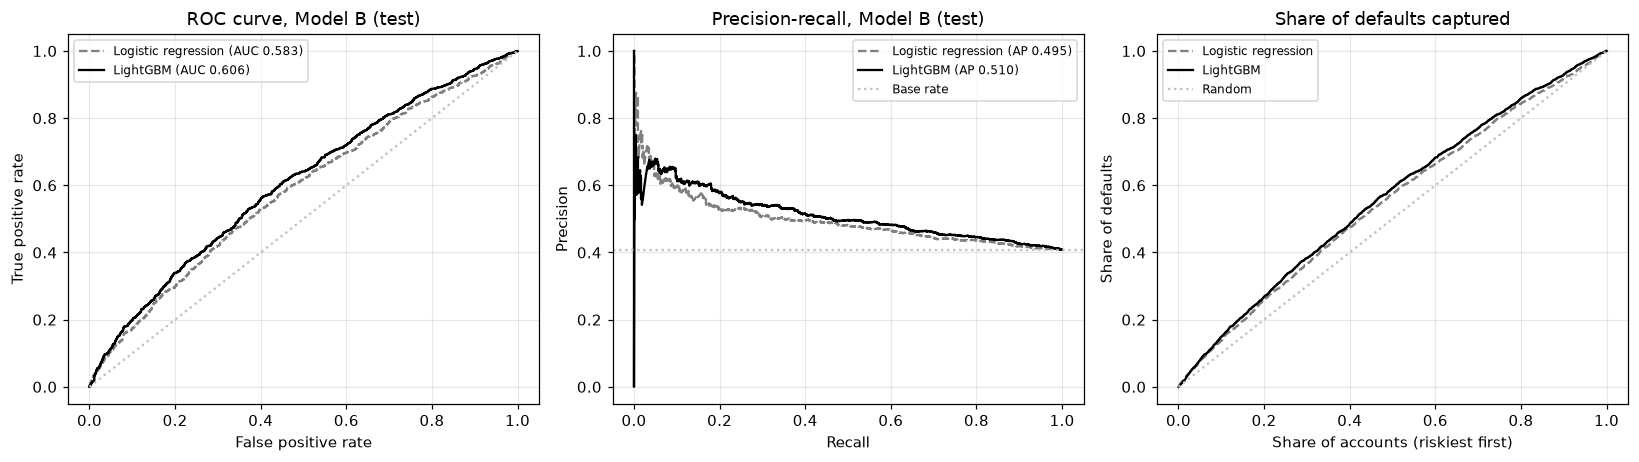

In [149]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
styles = {'Logistic regression': ('gray', '--'), 'LightGBM': ('black', '-')}
from sklearn.metrics import roc_curve, precision_recall_curve
for name, s in resB['scores'].items():
    colour, line = styles[name]
    fpr, tpr, _ = roc_curve(yte, s)
    ax[0].plot(fpr, tpr, color=colour, ls=line, label=f'{name} (AUC {roc_auc_score(yte, s):.3f})')
    precision, recall, _ = precision_recall_curve(yte, s)
    ax[1].plot(recall, precision, color=colour, ls=line, label=f'{name} (AP {average_precision_score(yte, s):.3f})')
    share_called = np.arange(1, len(yte) + 1) / len(yte)
    ax[2].plot(share_called, np.cumsum(yte[np.argsort(-s)]) / yte.sum(), color=colour, ls=line, label=name)
ax[0].plot([0, 1], [0, 1], ':', color='silver')
ax[0].set(title='ROC curve, Model B (test)', xlabel='False positive rate', ylabel='True positive rate')
ax[1].axhline(yte.mean(), ls=':', color='silver', label='Base rate')
ax[1].set(title='Precision-recall, Model B (test)', xlabel='Recall', ylabel='Precision')
ax[2].plot([0, 1], [0, 1], ':', color='silver', label='Random')
ax[2].set(title='Share of defaults captured', xlabel='Share of accounts (riskiest first)', ylabel='Share of defaults')
for a in ax:
    a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG, '02_roc_pr_gain.png'), bbox_inches='tight')
plt.show()

The model lines sit above the dotted random lines, but not far above, which matches our AUC.

### 7.5 Calibration chart

Each point compares the average predicted probability in a group of accounts with the actual default rate. Points on the diagonal mean well calibrated.

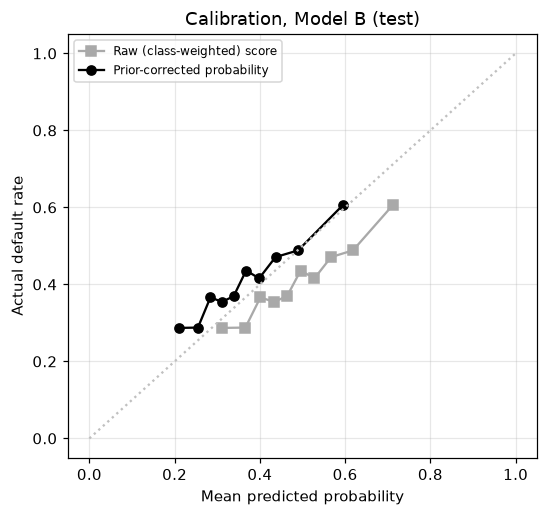

In [150]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5.5, 5))
actual, predicted = calibration_curve(yte, s_best, n_bins=10, strategy='quantile')
ax.plot(predicted, actual, marker='s', color='darkgray', label='Raw (class-weighted) score')
actual, predicted = calibration_curve(yte, p_best, n_bins=10, strategy='quantile')
ax.plot(predicted, actual, marker='o', color='black', label='Prior-corrected probability')
ax.plot([0, 1], [0, 1], ':', color='silver')
ax.set(title='Calibration, Model B (test)', xlabel='Mean predicted probability', ylabel='Actual default rate')
ax.legend(fontsize=8)
plt.savefig(os.path.join(FIG, '03_calibration.png'), bbox_inches='tight')
plt.show()

The corrected line is closer to the diagonal than the raw line. Points are spread over a narrow range of actual rates, again showing modest separation.

### 7.6 Confusion matrix at a probability of 0.5

Accounts with a corrected probability of 0.5 or more are flagged as high risk. Precision = share of flagged accounts that defaulted. Recall = share of defaulters that were flagged.

In [151]:
THRESH = 0.5
flagged = (p_best >= THRESH).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, flagged).ravel()
conf = pd.DataFrame([[tn, fp], [fn, tp]], index=['Actual: repaid by day 30', 'Actual: default_30'],
                    columns=['Predicted low risk', 'Predicted high risk'])
conf_stats = {'threshold': THRESH, 'flagged_share': flagged.mean(), 'precision': tp / (tp + fp),
              'recall': tp / (tp + fn), 'false_positive_rate': fp / (fp + tn)}
conf.to_csv(os.path.join(OUT, 'confusion_matrix_test.csv'))
print({k: round(float(v), 3) for k, v in conf_stats.items()})
conf

{'threshold': 0.5, 'flagged_share': 0.134, 'precision': 0.581, 'recall': 0.191, 'false_positive_rate': 0.095}


,Predicted low risk,Predicted high risk
Actual: repaid by day 30,1844,193
Actual: default_30,1137,268


## Step 8: Check the model is sound (leakage, time gap, operating point)

Before we build anything on top of Model B we check three things. First, that no single feature predicts the outcome suspiciously well, which would hint that it carries information from after the scoring point. Second, that `phone_valid` (the strongest driver) is a fixed fact about the customer and not something updated after collections calls. Third, how much the model loses when there is a realistic 30-day gap between the training outcomes and the test period.

### 8.1 How well does each feature predict on its own?

For every number feature we work out its AUC on the test set on its own. A value above about 0.8 for a single feature would be a warning sign of leakage.

In [152]:
single_rows = []
for col in NUM:
    values = test[col].astype(float)
    has_value = values.notna()
    if has_value.sum() > 50 and values[has_value].nunique() > 1:
        auc = roc_auc_score(test.loc[has_value, 'default_30'].astype(int), values[has_value])
        single_rows.append({'feature': col, 'single_feature_auc': round(max(auc, 1 - auc), 3)})
single = pd.DataFrame(single_rows).sort_values('single_feature_auc', ascending=False)
single.to_csv(os.path.join(OUT, 'leakage_check_single_feature_auc.csv'), index=False)
single.head(8)

,feature,single_feature_auc
21,credit_score,0.552
29,phone_valid,0.551
36,sms_invalid_number,0.545
33,pre_due_sms_delivered,0.545
8,n_payment_attempts_before_scoring,0.538
9,n_failed_attempts_before_scoring,0.538
35,sms_failed_before_scoring,0.537
4,customer_loan_number,0.536


The strongest single feature is `credit_score` at about 0.55, followed by `phone_valid`. Nothing comes close to 0.8, so there is no sign of leakage.

### 8.2 Is `phone_valid` a fixed fact or a result of collections?

If `phone_valid` were switched to N after a wrong-number call, it would leak call results into the model. We look at the **very first SMS** ever sent to each customer, long before any collections call.

In [153]:
first_sms = sms.sort_values('ts').groupby('CUSTOMER_ID').first()
first_sms['PHONE_VALID'] = first_sms.index.map(cust.set_index('CUSTOMER_ID')['PHONE_VALID'])
phone_check = pd.crosstab(first_sms['PHONE_VALID'], first_sms['FAILURE_CODE'].fillna('Delivered'))
phone_check.to_csv(os.path.join(OUT, 'check_phone_valid_first_sms.csv'))
phone_check

FAILURE_CODE,CARRIER_REJECTED,Delivered,HANDSET_UNREACHABLE,INVALID_NUMBER,SENDER_ID_BLOCKED
PHONE_VALID,,,,,
N,0,0,0,1188,0
Y,670,8289,660,0,6373


The result showed that every customer with `PHONE_VALID = N` had their very first SMS fail as `INVALID_NUMBER`, and no customer with `Y` ever had that failure. So the flag describes the number the customer gave at sign-up, which is known before scoring. It is safe to use.

### 8.3 Retrain with a 30-day gap

In Step 5 the training loans run up to 30 June, but their 30-day outcomes are only known by 30 July. In real use on 1 July the team would only know outcomes for loans due by 31 May. We retrain on loans due before 1 June with the same settings and score the same test loans.

In [154]:
gap_rows = []
for label, table, test_table, tuning in [('B (day 1)', F, test, tuning_B), ('A (due date)', FA, testA, tuning_A)]:
    for train_end in [pd.Timestamp('2026-07-01'), pd.Timestamp('2026-06-01')]:
        tr = table[table['DUE_DATE'] < train_end]
        y_tr = tr['default_30'].astype(int).values
        X_tr, (X_te,) = lgb_frames(tr, [test_table])
        m = make_lgbm(best_setting(tuning, 'LightGBM'), (y_tr == 0).sum() / (y_tr == 1).sum()).fit(X_tr, y_tr)
        s = m.predict_proba(X_te)[:, 1]
        y_te = test_table['default_30'].astype(int).values
        gap_rows.append({'model': label, 'train_due_before': train_end.date(), 'train_loans': len(tr),
                         'test_auc': round(roc_auc_score(y_te, s), 4), 'test_pr_auc': round(average_precision_score(y_te, s), 4)})
gap_check = pd.DataFrame(gap_rows)
gap_check.to_csv(os.path.join(OUT, 'robustness_gap_check.csv'), index=False)
gap_check

,model,train_due_before,train_loans,test_auc,test_pr_auc
0,B (day 1),2026-07-01,2588,0.6056,0.5103
1,B (day 1),2026-06-01,1798,0.5727,0.4694
2,A (due date),2026-07-01,16202,0.6929,0.2442
3,A (due date),2026-06-01,12914,0.6893,0.2454


The first row for each model repeats Step 7. With the realistic gap, Model B drops from about 0.61 to about 0.57 and Model A moves only a little. Model B is trained on few loans, so the most recent months matter a lot to it. Quote the gap figure as the cautious estimate of live performance.

### 8.4 Precision and recall at different cut-offs

The 0.5 probability cut-off in Step 7 flags only 13% of accounts. The call list does not use a cut-off at all, it ranks accounts, but it helps to see the trade-off if Risk want a "high risk" flag.

In [155]:
op_rows = []
for label, thr in [('Probability 0.50 (Step 7)', 0.5), ('Top 10% of scores', np.quantile(p_best, 0.9)),
                   ('Top 20% of scores', np.quantile(p_best, 0.8)), ('Top 30% of scores', np.quantile(p_best, 0.7))]:
    flag = p_best >= thr
    tp = int((flag & (yte == 1)).sum())
    op_rows.append({'cut_off': label, 'probability_threshold': round(float(thr), 3), 'flagged_share': round(flag.mean(), 3),
                    'precision': round(tp / flag.sum(), 3), 'recall': round(tp / (yte == 1).sum(), 3)})
operating_points = pd.DataFrame(op_rows)
operating_points.to_csv(os.path.join(OUT, 'operating_points_model_B.csv'), index=False)
operating_points

,cut_off,probability_threshold,flagged_share,precision,recall
0,Probability 0.50 (Step 7),0.500,0.134,0.581,0.191
1,Top 10% of scores,0.531,0.100,0.606,0.149
2,Top 20% of scores,0.459,0.200,0.547,0.268
3,Top 30% of scores,0.416,0.300,0.522,0.384


As the cut-off widens, recall rises and precision falls towards the 40.8% base rate. At the 0.5 cut-off precision is 58.1% and recall 19.1%.

## Step 9: Explain the model with SHAP

SHAP values show how much each feature pushed an account's score up or down. The summary shows the main drivers overall. The worked examples explain three individual accounts (high, middle and low risk).

### 9.1 Calculate SHAP values for the test accounts

In [156]:
import shap
explainer = shap.TreeExplainer(resB['lgbm'])
Xte = resB['X_test']
sv = explainer.shap_values(Xte)
if isinstance(sv, list):          # older shap versions return one array per class
    sv = sv[1]
base_value = explainer.expected_value
if np.ndim(base_value) > 0:
    base_value = base_value[-1]
print('SHAP values shape:', sv.shape)

SHAP values shape: (3442, 51)


### 9.2 Rank features by average impact

The mean absolute SHAP value tells us how much a feature moves the score on average, whichever direction.

In [157]:
importance = pd.DataFrame({'feature': FEATURES, 'mean_abs_shap': np.abs(sv).mean(axis=0)})
importance = importance.sort_values('mean_abs_shap', ascending=False)
importance.round(4).to_csv(os.path.join(OUT, 'shap_importance_model_B.csv'), index=False)
importance.head(15).round(4)

,feature,mean_abs_shap
30,phone_valid,0.1428
22,credit_score,0.1211
36,sms_failed_before_scoring,0.1046
8,n_payment_attempts_before_scoring,0.0846
46,last_failure_reason,0.0739
49,acquisition_channel,0.0662
0,principal_gbp,0.0637
33,days_since_payday_at_due,0.0600
31,tenure_days_at_disbursement,0.0581
24,enquiries_6m,0.0539


### 9.3 SHAP summary chart

Each dot is one test account. Dots to the right push risk up. Dark dots are high feature values, light dots are low values.

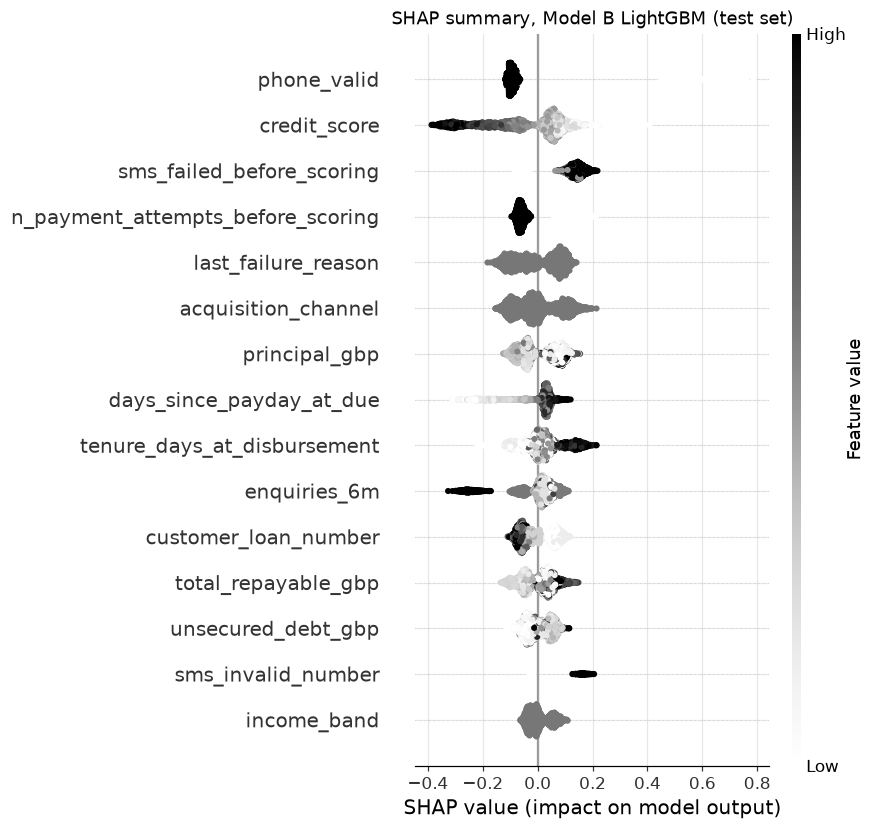

In [158]:
plt.figure()
shap.summary_plot(sv, Xte, max_display=15, show=False, cmap=matplotlib.colormaps['Greys'])
plt.title('SHAP summary, Model B LightGBM (test set)')
plt.savefig(os.path.join(FIG, '04_shap_summary.png'), bbox_inches='tight')
plt.show()

### 9.4 Explain three individual accounts in words

We take the highest-risk, a middle and the lowest-risk test account and list the five features that moved each score most.

In [159]:
order = np.argsort(-s_best)
examples = {'High risk': order[0], 'Middle risk': order[len(order) // 2], 'Low risk': order[-1]}
example_rows = []
for label, i in examples.items():
    contributions = pd.Series(sv[i], index=FEATURES)
    top5 = contributions.reindex(contributions.abs().sort_values(ascending=False).index).head(5)
    print(f'{label}: loan {test.loc[i, "LOAN_ID"]}, predicted probability {p_best[i]:.2f}, actually defaulted: {bool(yte[i])}')
    for feature, value in top5.items():
        direction = 'UP' if value > 0 else 'DOWN'
        print(f'    {feature} = {test.loc[i, feature]}  pushes risk {direction} ({value:+.2f})')
        example_rows.append({'example': label, 'loan_id': test.loc[i, 'LOAN_ID'], 'predicted_prob': round(float(p_best[i]), 3),
                             'actual_default_30': bool(yte[i]), 'feature': feature, 'value': test.loc[i, feature], 'shap': round(float(value), 3)})
    print()
shap_examples = pd.DataFrame(example_rows)
shap_examples.to_csv(os.path.join(OUT, 'shap_examples.csv'), index=False)

High risk: loan L1029882, predicted probability 0.73, actually defaulted: False
    phone_valid = 0  pushes risk UP (+0.50)
    tenure_days_at_disbursement = 1147  pushes risk UP (+0.14)
    sms_invalid_number = 1.0  pushes risk UP (+0.14)
    sms_failed_before_scoring = 2.0  pushes risk UP (+0.11)
    n_payment_attempts_before_scoring = 0.0  pushes risk UP (+0.07)

Middle risk: loan L1037966, predicted probability 0.35, actually defaulted: False
    days_since_payday_at_due = 3.0  pushes risk DOWN (-0.22)
    sms_failed_before_scoring = 2.0  pushes risk UP (+0.19)
    acquisition_channel = Comparison site  pushes risk UP (+0.10)
    phone_valid = 1  pushes risk DOWN (-0.10)
    principal_gbp = 270  pushes risk UP (+0.10)

Low risk: loan L1035326, predicted probability 0.14, actually defaulted: False
    credit_score = 692.0  pushes risk DOWN (-0.31)
    employment_status = Unknown  pushes risk DOWN (-0.13)
    last_failure_reason = PROCESSOR_TIMEOUT  pushes risk DOWN (-0.12)
    acqui

### 9.5 Main drivers of Model A

For comparison we rank the early-warning model's features the same way.

In [160]:
svA = shap.TreeExplainer(resA['lgbm']).shap_values(resA['X_test'])
if isinstance(svA, list):
    svA = svA[1]
importance_A = pd.DataFrame({'feature': FEATURES, 'mean_abs_shap': np.abs(svA).mean(axis=0)})
importance_A = importance_A.sort_values('mean_abs_shap', ascending=False)
importance_A.round(4).to_csv(os.path.join(OUT, 'shap_importance_model_A.csv'), index=False)
importance_A.head(10).round(4)

,feature,mean_abs_shap
34,pre_due_sms_delivered,0.3099
22,credit_score,0.2885
45,repayment_method,0.2680
33,days_since_payday_at_due,0.1168
47,employment_status,0.1085
4,customer_loan_number,0.0908
1,total_repayable_gbp,0.0827
36,sms_failed_before_scoring,0.0660
30,phone_valid,0.0593
0,principal_gbp,0.0547


## Step 10: Fairness checks (C3)

Even without age or region as inputs, a model can treat groups differently through other features. For each group we compare, on the test set at the 0.5 threshold:
- **flagged rate** (share predicted high risk) against the **actual default rate**;
- **false positive rate** (good payers wrongly flagged) and **false negative rate** (defaulters missed);
- **calibration gap** (average predicted probability minus actual rate) and **AUC within the group**.

Under the FCA Consumer Duty, being flagged should lead to **more support** (earlier contact, affordable payment plans), never harsher treatment. Groups with fewer than 100 loans are marked as small because their rates are noisy.

### 10.1 A function that measures one attribute

Given a table with `risk_score` and `default_30`, it returns one row per group.

In [161]:
def group_metrics(df, attribute, threshold):
    rows = []
    for group, g in df.groupby(attribute):
        y = g['default_30'].astype(int).values
        prob = g['risk_score'].values
        flagged = prob >= threshold
        negatives = (y == 0).sum()
        positives = (y == 1).sum()
        rows.append({'attribute': attribute, 'group': group, 'loans': len(g),
                     'actual_default_rate': y.mean(), 'flagged_rate': flagged.mean(),
                     'false_positive_rate': (flagged & (y == 0)).sum() / negatives if negatives else np.nan,
                     'false_negative_rate': (~flagged & (y == 1)).sum() / positives if positives else np.nan,
                     'mean_predicted': prob.mean(), 'calibration_gap': prob.mean() - y.mean(),
                     'group_auc': roc_auc_score(y, prob) if 0 < positives < len(y) else np.nan,
                     'small_group': len(g) < 100})
    return rows

### 10.2 Fairness table for Model B

We check age band, region, employment status and income band. Saved to `outputs/fairness_by_group_model_B.csv`.

In [162]:
fair_rows = []
for attribute in ['age_band', 'region', 'employment_status', 'income_band']:
    fair_rows = fair_rows + group_metrics(test, attribute, THRESH)
fair = pd.DataFrame(fair_rows).round(3)
fair.to_csv(os.path.join(OUT, 'fairness_by_group_model_B.csv'), index=False)
fair

,attribute,group,loans,actual_default_rate,flagged_rate,false_positive_rate,false_negative_rate,mean_predicted,calibration_gap,group_auc,small_group
0,age_band,18-24,700,0.401,0.117,0.074,0.819,0.363,-0.038,0.599,False
1,age_band,25-34,1181,0.391,0.152,0.113,0.788,0.373,-0.018,0.589,False
2,age_band,35-44,1122,0.412,0.126,0.086,0.818,0.366,-0.046,0.619,False
3,age_band,45+,439,0.456,0.134,0.100,0.825,0.370,-0.086,0.625,False
4,region,East Midlands,223,0.386,0.121,0.080,0.814,0.358,-0.028,0.607,False
5,region,East of England,192,0.385,0.135,0.085,0.784,0.367,-0.019,0.590,False
6,region,London,545,0.385,0.121,0.087,0.824,0.360,-0.026,0.633,False
7,region,North East,131,0.389,0.099,0.012,0.765,0.351,-0.039,0.680,False
8,region,North West,481,0.426,0.146,0.130,0.834,0.378,-0.048,0.556,False
9,region,Northern Ireland,183,0.355,0.120,0.068,0.785,0.365,0.010,0.606,False


### 10.3 Summarise the spread between groups

For each attribute we show the lowest and highest value across groups (ignoring small groups). A wide range means the model behaves differently across those groups.

In [163]:
large = fair[~fair['small_group']]
spread = large.groupby('attribute').agg(
    fpr_min=('false_positive_rate', 'min'), fpr_max=('false_positive_rate', 'max'),
    fnr_min=('false_negative_rate', 'min'), fnr_max=('false_negative_rate', 'max'),
    calibration_gap_min=('calibration_gap', 'min'), calibration_gap_max=('calibration_gap', 'max'),
    auc_min=('group_auc', 'min'), auc_max=('group_auc', 'max'))
spread.round(3)

,fpr_min,fpr_max,fnr_min,fnr_max,calibration_gap_min,calibration_gap_max,auc_min,auc_max
attribute,,,,,,,,
age_band,0.074,0.113,0.788,0.825,-0.086,-0.018,0.589,0.625
employment_status,0.067,0.131,0.746,0.826,-0.075,-0.012,0.585,0.717
income_band,0.072,0.126,0.783,0.847,-0.055,0.007,0.567,0.624
region,0.012,0.149,0.756,0.841,-0.073,0.010,0.556,0.680


### 10.4 Fairness table for Model A


In [164]:
testA['risk_score'] = resA['probs']['LightGBM']
THRESH_A = float(np.quantile(testA['risk_score'], 0.8))       # top 20% of accounts are flagged
fairA_rows = []
for attribute in ['age_band', 'region', 'employment_status', 'income_band']:
    fairA_rows = fairA_rows + group_metrics(testA, attribute, THRESH_A)
fairA = pd.DataFrame(fairA_rows).round(3)
fairA.to_csv(os.path.join(OUT, 'fairness_by_group_model_A.csv'), index=False)
print('Model A threshold (top 20%):', round(THRESH_A, 3))
fairA.groupby('attribute')[['false_positive_rate', 'false_negative_rate', 'calibration_gap']].agg(['min', 'max']).round(3)

Model A threshold (top 20%): 0.095


false_positive_rate        false_negative_rate        calibration_gap       
                                  min    max                 min    max             min    max
attribute                                                                                     
age_band                        0.162  0.180               0.545  0.573          -0.054 -0.037
employment_status               0.117  0.216               0.414  0.739          -0.065 -0.035
income_band                     0.139  0.187               0.482  0.607          -0.049 -0.029
region                          0.142  0.197               0.471  0.663          -0.061 -0.030

## Step 11: Save the models for daily use

The daily call list needs the trained model saved to a file. `train_and_save_models.py` rebuilds the model tables with the same code as this notebook in `compass_core.py`, refits each model on **every** loan with a known outcome and saves it with joblib in the `models` folder. The version trained only on loans due before 1 July is saved as well as`..._evaluated.joblib` and Step 16 uses it so no test outcome leaks into the comparison.

In [165]:
import importlib, compass_core, train_and_save_models
importlib.reload(compass_core); importlib.reload(train_and_save_models)
train_and_save_models.main()
print(sorted(os.listdir('models')))

Model B: test AUC of the evaluated model 0.6056 (notebook value should match); production refit on 6,030 loans saved to models/model_B_day1.joblib
Model A: test AUC of the evaluated model 0.6929 (notebook value should match); production refit on 28,938 loans saved to models/model_A_due_date.joblib
['model_A_due_date.joblib', 'model_A_due_date_evaluated.joblib', 'model_B_day1.joblib', 'model_B_day1_evaluated.joblib', 'model_card.json']


## Step 12: Agent capacity

The 24 agents cannot call everyone, so the order of the list matters. We first measure how many calls the team makes in a day from the call log.

### 12.1 Count calls, agents and accounts per day

We group the call log by day.

In [166]:
calls['day'] = calls['ts'].dt.normalize()
per_day = calls.groupby('day').agg(calls=('CALL_ID', 'size'), agents=('AGENT_ID', 'nunique'), accounts=('LOAN_ID', 'nunique'))
calls_per_month = calls.groupby(calls['ts'].dt.to_period('M')).size()
print('Calls per month:')
print(calls_per_month.to_string())

Calls per month:
ts
2025-10       3
2025-11     130
2025-12     298
2026-01     422
2026-02     442
2026-03     700
2026-04     715
2026-05    1365
2026-06    2333
2026-07    3093
2026-08    3473
2026-09    3204
2026-10    3140
2026-11     264
Freq: M


**What you should see:** calls per month rising from a handful in October 2025 to about 3,000 a month from July 2026.

### 12.2 Capacity in the test period

We look at July to October 2026, the same period as the test loans.

In [167]:
window = per_day[(per_day.index >= SPLIT) & (per_day.index <= pd.Timestamp('2026-10-31'))]
calls_in_window = calls[calls['day'].isin(window.index)]
cap = {
    'days_with_calls': int(len(window)),
    'calls_per_day_mean': float(window['calls'].mean()),
    'calls_per_day_median': float(window['calls'].median()),
    'accounts_per_day_median': float(window['accounts'].median()),
    'agents_active_per_day_mean': float(window['agents'].mean()),
    'calls_per_active_agent_day': float(calls_in_window.groupby(['day', 'AGENT_ID']).size().mean()),
    'weekdays_with_calls': sorted(calls['ts'].dt.day_name().unique()),
}
for k, v in cap.items():
    print(k, ':', round(v, 1) if isinstance(v, float) else v)

days_with_calls : 106
calls_per_day_mean : 121.8
calls_per_day_median : 94.0
accounts_per_day_median : 94.0
agents_active_per_day_mean : 23.1
calls_per_active_agent_day : 5.3
weekdays_with_calls : ['Friday', 'Monday', 'Saturday', 'Thursday', 'Tuesday', 'Wednesday']


**What you should see:** the average and median calls per day, how many agents were active, and the weekdays with calls. There are no Sunday calls in the log.

### 12.3 A first look: the top 20% of the test accounts

`expected_loss` = risk score x balance. `at_risk` = the balance if the loan really defaulted, otherwise 0 (this is what we want the list to reach). We sort the test accounts four ways (alphabetical by surname as today, random, risk only, and risk x balance) and see how much of the defaulting balance falls in the first 20%.

In [168]:
rng = np.random.default_rng(0)                      # fixed seed so the random order is repeatable
sim_df = test.copy()
sim_df['expected_loss'] = sim_df['risk_score'] * sim_df['balance_at_scoring']
sim_df['random_order'] = rng.random(len(sim_df))
sim_df['at_risk'] = sim_df['balance_at_scoring'] * sim_df['default_30']
orders = {'Alphabetical (current)': (['LAST_NAME', 'FIRST_NAME'], True),
          'Random': (['random_order'], True),
          'Risk only': (['risk_score'], False),
          'Risk x balance': (['expected_loss'], False)}
cohort_rows = []
for name, (cols, ascending) in orders.items():
    top = sim_df.sort_values(cols, ascending=ascending).head(int(0.2 * len(sim_df)))
    cohort_rows.append({'ordering': name,
                        'top20_share_of_defaulting_balance': top['at_risk'].sum() / sim_df['at_risk'].sum(),
                        'top20_share_of_defaults': top['default_30'].sum() / sim_df['default_30'].sum()})
cohort = pd.DataFrame(cohort_rows).round(4)
cohort.to_csv(os.path.join(OUT, 'call_list_top20_cohort.csv'), index=False)
cohort

,ordering,top20_share_of_defaulting_balance,top20_share_of_defaults
0,Alphabetical (current),0.1426,0.1502
1,Random,0.1952,0.1957
2,Risk only,0.2639,0.2676
3,Risk x balance,0.4592,0.2548


## Step 13: Contact history analysis for the contact strategy (C4)

To choose channel, timing and message, we look at what has happened after past contacts. These are **observational** comparisons, not experiments: for example, people who open a message may already be more likely to pay. Use them to design an A/B test but not as proof of effect.

### 13.1 A helper: did a successful payment follow within 48 hours?

For each contact (SMS, nudge or call) we check whether the same loan had a successful payment in the next 48 hours.

In [169]:
successes = pay[pay['PAYMENT_STATUS'] == 'Success'][['LOAN_ID', 'ts']].rename(columns={'ts': 'pay_ts'})

def paid_within(contacts, hours=48):
    m = contacts[['LOAN_ID', 'ts']].reset_index().merge(successes, on='LOAN_ID', how='left')
    in_window = (m['pay_ts'] > m['ts']) & (m['pay_ts'] <= m['ts'] + pd.Timedelta(hours=hours))
    result = in_window.groupby(m['index']).any()          # True if any payment fell in the window
    return result.reindex(contacts.index).fillna(False)

### 13.2 SMS delivery by message type and route

Delivery is the first hurdle: an SMS that fails cannot work.

In [170]:
sms['paid_48h'] = paid_within(sms)
sms['delivered'] = sms['DELIVERY_STATUS'] == 'DELIVERED'
sms_delivery = sms.groupby(['MESSAGE_TYPE', 'SMS_ROUTE']).agg(sent=('SMS_ID', 'size'), delivered_rate=('delivered', 'mean')).round(3)
sms_delivery.to_csv(os.path.join(OUT, 'c4_sms_delivery.csv'))
print('Failure codes:', sms['FAILURE_CODE'].value_counts().to_dict())
sms_delivery

Failure codes: {'SENDER_ID_BLOCKED': 18571, 'INVALID_NUMBER': 6627, 'CARRIER_REJECTED': 707, 'HANDSET_UNREACHABLE': 697}


sent  delivered_rate
MESSAGE_TYPE      SMS_ROUTE                       
DUE_DAY_REMINDER  ROUTE_A    27425           0.908
                  ROUTE_B    10893           0.238
OVERDUE_NOTICE_D1 ROUTE_A     3285           0.837
                  ROUTE_B     2546           0.247
OVERDUE_NOTICE_D3 ROUTE_A     3205           0.844
                  ROUTE_B     2520           0.218
PRE_DUE_REMINDER  ROUTE_A    27556           0.908
                  ROUTE_B    10829           0.233

Delivery rates by message type and route, and the main failure codes.

### 13.3 Payment after overdue SMS

For day 1 and day 3 overdue notices, how often a payment followed within 48 hours, split by delivered or failed.

In [171]:
overdue_sms = sms[sms['MESSAGE_TYPE'].str.startswith('OVERDUE')].copy()
overdue_response = overdue_sms.groupby(['MESSAGE_TYPE', 'DELIVERY_STATUS']).agg(
    sent=('SMS_ID', 'size'), paid_within_48h=('paid_48h', 'mean')).round(3)
overdue_response.to_csv(os.path.join(OUT, 'c4_overdue_sms_response.csv'))
print('Overdue SMS send hours:', overdue_sms['ts'].dt.hour.value_counts().sort_index().to_dict())
overdue_response

Overdue SMS send hours: {9: 11556}


sent  paid_within_48h
MESSAGE_TYPE      DELIVERY_STATUS                       
OVERDUE_NOTICE_D1 DELIVERED        3377            0.017
                  FAILED           2454            0.013
OVERDUE_NOTICE_D3 DELIVERED        3254            0.055
                  FAILED           2471            0.044

Payment rates within 48 hours for each overdue notice. All overdue SMS are sent at 09:00, so the data cannot tell us whether another time of day would work better.

### 13.4 Email, push and WhatsApp nudges

Open, click and pay-within-48-hours rates by channel.

In [172]:
nud['paid_48h'] = paid_within(nud)
nud['opened'] = nud['OPENED'] == 'Y'
nud['clicked'] = nud['CLICKED'] == 'Y'
nudge_table = nud.groupby('CHANNEL').agg(sent=('NUDGE_ID', 'size'), open_rate=('opened', 'mean'),
                                          click_rate=('clicked', 'mean'), paid_within_48h=('paid_48h', 'mean')).round(3)
nudge_table.to_csv(os.path.join(OUT, 'c4_nudges.csv'))
nudge_table

,sent,open_rate,click_rate,paid_within_48h
CHANNEL,,,,
Email,918,0.230,0.106,0.038
In-app push,926,0.434,0.192,0.044
WhatsApp,694,0.726,0.379,0.058


### 13.5 Call outcomes by hour and weekday

**Right-party contact (RPC)** means the agent spoke to the customer. **Promise to pay (PTP)** means they agreed a payment date.

In [173]:
calls['rpc'] = calls['CALL_OUTCOME'].str.startswith('Spoke')
calls['ptp'] = calls['CALL_OUTCOME'] == 'Spoke - promise to pay'
calls['hour'] = calls['ts'].dt.hour
calls['weekday'] = calls['ts'].dt.day_name()
print('Call outcomes:', calls['CALL_OUTCOME'].value_counts(normalize=True).round(3).to_dict())
by_hour = calls.groupby('hour').agg(calls=('CALL_ID', 'size'), rpc_rate=('rpc', 'mean'), ptp_rate=('ptp', 'mean')).round(3)
by_weekday = calls.groupby('weekday').agg(calls=('CALL_ID', 'size'), rpc_rate=('rpc', 'mean'), ptp_rate=('ptp', 'mean')).round(3)
by_hour.to_csv(os.path.join(OUT, 'c4_calls_by_hour.csv'))
by_weekday.to_csv(os.path.join(OUT, 'c4_calls_by_weekday.csv'))
display(by_hour)
by_weekday

Call outcomes: {'No answer': 0.346, 'Spoke - promise to pay': 0.205, 'Voicemail': 0.191, 'Wrong number': 0.126, 'Spoke - query raised': 0.066, 'Spoke - refused to pay': 0.066}


,calls,rpc_rate,ptp_rate
hour,,,
9,1133,0.240,0.145
10,1165,0.254,0.151
11,1208,0.297,0.181
12,2159,0.317,0.191
13,2303,0.329,0.198
14,2243,0.329,0.211
15,2262,0.316,0.191
16,2297,0.331,0.208
17,2665,0.422,0.255


,calls,rpc_rate,ptp_rate
weekday,,,
Friday,2682,0.388,0.278
Monday,6787,0.314,0.175
Saturday,1849,0.372,0.261
Thursday,4423,0.263,0.092
Tuesday,1563,0.292,0.141
Wednesday,2278,0.490,0.426


### 13.6 Were promises to pay kept?

A promise counts as kept if a successful payment arrived by the promised date plus one day.

In [174]:
promises = calls[calls['ptp'] & calls['PROMISE_TO_PAY_DATE'].notna()].reset_index()
pm = promises.merge(successes, on='LOAN_ID', how='left')
kept_rows = (pm['pay_ts'] > pm['ts']) & (pm['pay_ts'] < pm['PROMISE_TO_PAY_DATE'] + pd.Timedelta(days=2))
kept = kept_rows.groupby(pm['index']).any()
ptp_kept = float(kept.mean())
print(f'Promises to pay: {len(promises):,}; kept: {ptp_kept:.1%}')

Promises to pay: 4,011; kept: 68.4%


### 13.7 Call outcomes by days past due, and payment after each outcome

Is it easier to reach people early in arrears? And how often does a payment follow each outcome?

In [175]:
due_dates = loans.set_index('LOAN_ID')['DUE_DATE']
calls['days_past_due'] = (calls['day'] - calls['LOAN_ID'].map(due_dates)).dt.days
calls['dpd_band'] = pd.cut(calls['days_past_due'], [0, 3, 7, 14, 30, 400], labels=['1-3', '4-7', '8-14', '15-30', '31+'])
by_dpd = calls.groupby('dpd_band').agg(calls=('CALL_ID', 'size'), rpc_rate=('rpc', 'mean'), ptp_rate=('ptp', 'mean')).round(3)
by_dpd.to_csv(os.path.join(OUT, 'c4_calls_by_days_past_due.csv'))
calls['paid_48h'] = paid_within(calls)
after_call = calls.groupby('CALL_OUTCOME')['paid_48h'].mean().round(3)
after_call.to_csv(os.path.join(OUT, 'c4_payment_after_call_outcome.csv'))
display(by_dpd)
after_call

,calls,rpc_rate,ptp_rate
dpd_band,,,
1-3,1684,0.346,0.262
4-7,4820,0.393,0.297
8-14,8137,0.363,0.234
15-30,4872,0.236,0.048
31+,69,0.217,0.000


CALL_OUTCOME
No answer                 0.034
Spoke - promise to pay    0.435
Spoke - query raised      0.024
Spoke - refused to pay    0.000
Voicemail                 0.045
Wrong number              0.047
Name: paid_48h, dtype: float64

### 13.8 Chart of call outcomes by hour and weekday

Bars show right-party contact; the black line shows promises to pay.

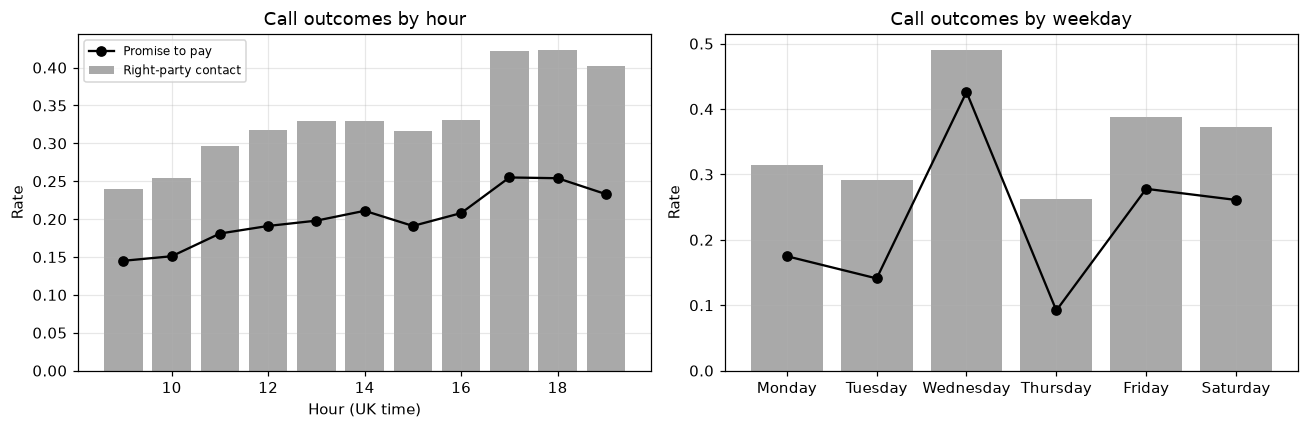

In [176]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(by_hour.index, by_hour['rpc_rate'], color='darkgray', label='Right-party contact')
ax[0].plot(by_hour.index, by_hour['ptp_rate'], 'k-o', label='Promise to pay')
ax[0].set(title='Call outcomes by hour', xlabel='Hour (UK time)', ylabel='Rate')
ax[0].legend(fontsize=8)
day_order = [d for d in ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'] if d in by_weekday.index]
ax[1].bar(day_order, by_weekday.loc[day_order, 'rpc_rate'], color='darkgray')
ax[1].plot(day_order, by_weekday.loc[day_order, 'ptp_rate'], 'k-o')
ax[1].set(title='Call outcomes by weekday', ylabel='Rate')
plt.tight_layout()
plt.savefig(os.path.join(FIG, '06_call_outcomes_hour_weekday.png'), bbox_inches='tight')
plt.show()

### 13.9 Repayment by days since payday

Using all loans with a known outcome, we compare on-time and default rates by how long after payday the due date falls.

In [177]:
known = loans[loans['outcome_30_known']].copy()
payday_map = cust.set_index('CUSTOMER_ID')['PAYDAY_DAY_OF_MONTH']
known['days_since_payday'] = [days_since_payday(d, pdom) for d, pdom in zip(known['DUE_DATE'], known['CUSTOMER_ID'].map(payday_map))]
known['payday_band'] = pd.cut(known['days_since_payday'], [-1, 3, 7, 14, 21, 31], labels=['0-3', '4-7', '8-14', '15-21', '22-31'])
known['payday_band'] = known['payday_band'].cat.add_categories(['Payday unknown'])   # add a label for blanks
known['payday_band'] = known['payday_band'].fillna('Payday unknown')                     # customers with no payday recorded
payday_table = known.groupby('payday_band', observed=False).agg(loans=('LOAN_ID', 'size'), on_time_rate=('on_time', 'mean'), default_30_rate=('default_30', 'mean')).round(3)
payday_table = payday_table.reindex(['0-3', '4-7', '8-14', '15-21', '22-31', 'Payday unknown'])   # put the bands in order
payday_table.to_csv(os.path.join(OUT, 'c4_payday_timing.csv'))
payday_table

,loans,on_time_rate,default_30_rate
payday_band,,,
0-3,2268,0.886,0.035
4-7,2576,0.852,0.055
8-14,4192,0.862,0.052
15-21,3538,0.864,0.047
22-31,4519,0.802,0.080
Payday unknown,20592,0.833,0.068


### 13.10 Repayment by employment status

Self-employed and gig workers have irregular income, which matters for message timing.

In [178]:
known = known.merge(cust[['CUSTOMER_ID', 'EMPLOYMENT_STATUS']], on='CUSTOMER_ID', how='left')
employment_table = known.groupby('EMPLOYMENT_STATUS').agg(loans=('LOAN_ID', 'size'), on_time_rate=('on_time', 'mean'), default_30_rate=('default_30', 'mean')).round(3)
employment_table.to_csv(os.path.join(OUT, 'c4_employment.csv'))
employment_table

,loans,on_time_rate,default_30_rate
EMPLOYMENT_STATUS,,,
Employed full-time,17069,0.858,0.052
Employed part-time,3852,0.828,0.065
Gig / contract,5844,0.817,0.079
Self-employed,7262,0.833,0.070
Student,1489,0.831,0.070
Unemployed,1551,0.798,0.075


### 13.11 Default rate by the reason the due-date payment failed

Within Model B's population, a technical failure may mean something different from insufficient funds.

In [179]:
failure_table = F.groupby('last_failure_reason').agg(loans=('LOAN_ID', 'size'), default_30_rate=('default_30', 'mean')).round(3)
failure_table = failure_table.sort_values('loans', ascending=False)
failure_table.to_csv(os.path.join(OUT, 'c4_failure_reason.csv'))
failure_table

,loans,default_30_rate
last_failure_reason,,
No failed attempt,1882,0.465
INSUFFICIENT_FUNDS,1510,0.417
PROCESSOR_TIMEOUT,1126,0.302
DO_NOT_HONOUR,935,0.348
AUTH_ERROR,322,0.311
CARD_EXPIRED,255,0.380


### 13.12 Contact results by risk band

We group Model B test accounts into Low (under 25%), Medium (25 to 50%) and High (50% and over) risk, then compare outcomes and contact results.

In [180]:
test['risk_band'] = pd.cut(test['risk_score'], [0, 0.25, 0.5, 1.0], labels=['Low (<25%)', 'Medium (25-50%)', 'High (50%+)'], include_lowest=True)
band_table = test.groupby('risk_band').agg(loans=('LOAN_ID', 'size'), default_30_rate=('default_30', 'mean'), mean_balance=('balance_at_scoring', 'mean'))
band_table['share_of_loans'] = band_table['loans'] / len(test)
band_calls = calls.merge(test[['LOAN_ID', 'risk_band']], on='LOAN_ID')
band_table = band_table.join(band_calls.groupby('risk_band').agg(calls=('CALL_ID', 'size'), rpc_rate=('rpc', 'mean'), ptp_rate=('ptp', 'mean')))
band_sms = overdue_sms[overdue_sms['delivered']].merge(test[['LOAN_ID', 'risk_band']], on='LOAN_ID')
band_table['paid_48h_after_overdue_sms'] = band_sms.groupby('risk_band')['paid_48h'].mean()
band_nudges = nud.merge(test[['LOAN_ID', 'risk_band']], on='LOAN_ID')
band_table['nudges'] = band_nudges.groupby('risk_band').size()
band_table['paid_48h_after_nudge'] = band_nudges.groupby('risk_band')['paid_48h'].mean()
band_table = band_table.round(3)
band_table.to_csv(os.path.join(OUT, 'c4_risk_band_contact_summary.csv'))
band_table

,loans,default_30_rate,mean_balance,share_of_loans,calls,rpc_rate,ptp_rate,paid_48h_after_overdue_sms,nudges,paid_48h_after_nudge
risk_band,,,,,,,,,,
Low (<25%),462,0.297,542.322,0.134,1340,0.404,0.266,0.043,187,0.048
Medium (25-50%),2519,0.397,609.969,0.732,7844,0.373,0.219,0.036,982,0.041
High (50%+),461,0.581,577.570,0.134,1608,0.124,0.072,0.053,188,0.027


## Step 14: More contact analysis for the contact strategy (C4)

Step 13 gave the first contact tables. Here we add the cuts the rules need: whether invalid phone numbers can ever be reached, which hours work for each kind of customer, how payday affects call results, how long agents usually leave between calls, and what happens after each call result. As in Step 13 these are observed patterns, not experiments, so they show what is worth trying rather than proving cause and effect.

### 14.1 Prepare the call table

We add the phone flag, employment status, an hour band, the team, and how many days after the customer's payday the call happened.

In [181]:
cmap = cust.set_index('CUSTOMER_ID')
calls['phone_valid'] = calls['CUSTOMER_ID'].map(cmap['PHONE_VALID'])
calls['employment'] = calls['CUSTOMER_ID'].map(cmap['EMPLOYMENT_STATUS']).fillna('Unknown')
calls['hour_band'] = pd.cut(calls['hour'], [8, 11, 16, 20], labels=['09:00-11:59', '12:00-16:59', '17:00-19:59'])
calls['team'] = np.where(calls['AGENT_ID'].str.startswith('A'), 'In-house (09:00-17:30)', 'Partner (12:00-20:00)')
calls['days_since_payday'] = [days_since_payday(d, p) for d, p in zip(calls['day'], calls['CUSTOMER_ID'].map(cmap['PAYDAY_DAY_OF_MONTH']))]
calls['payday_band'] = pd.cut(calls['days_since_payday'], [-1, 3, 7, 14, 21, 31], labels=['0-3', '4-7', '8-14', '15-21', '22-31'])
calls['payday_band'] = calls['payday_band'].cat.add_categories(['Payday unknown']).fillna('Payday unknown')
valid_calls = calls[calls['phone_valid'] == 'Y']
AGG = dict(calls=('CALL_ID', 'size'), rpc_rate=('rpc', 'mean'), ptp_rate=('ptp', 'mean'), paid_within_48h=('paid_48h', 'mean'))
print('Calls:', len(calls), '| to valid numbers:', len(valid_calls))

Calls: 19582 | to valid numbers: 17124


### 14.2 Can customers with an invalid phone number be reached by phone?

In [182]:
by_phone = calls.groupby('phone_valid').agg(**AGG).round(3)
by_phone.to_csv(os.path.join(OUT, 'c4_calls_by_phone_valid.csv'))
by_phone

,calls,rpc_rate,ptp_rate,paid_within_48h
phone_valid,,,,
N,2458,0.000,0.000,0.047
Y,17124,0.385,0.234,0.127


### 14.3 Which hours work best, and does it hold for every group?

We use only valid numbers so wrong numbers do not distort the picture, and split the hour bands by employment status, days past due and team.

In [183]:
hour_band = valid_calls.groupby('hour_band', observed=True).agg(**AGG).round(3)
hour_band.to_csv(os.path.join(OUT, 'c4_calls_by_hour_band.csv'))
hour_by_employment = valid_calls.pivot_table(index='employment', columns='hour_band', values='rpc', aggfunc='mean', observed=True).round(3)
hour_by_employment.to_csv(os.path.join(OUT, 'c4_rpc_by_hour_band_and_employment.csv'))
hour_by_dpd = valid_calls.pivot_table(index='dpd_band', columns='hour_band', values='rpc', aggfunc='mean', observed=True).round(3)
hour_by_dpd.to_csv(os.path.join(OUT, 'c4_rpc_by_hour_band_and_days_past_due.csv'))
hour_by_team = valid_calls.pivot_table(index='team', columns='hour_band', values='rpc', aggfunc='mean', observed=True).round(3)
hour_by_team.to_csv(os.path.join(OUT, 'c4_rpc_by_hour_band_and_team.csv'))
display(hour_band, hour_by_employment, hour_by_dpd)
hour_by_team

,calls,rpc_rate,ptp_rate,paid_within_48h
hour_band,,,,
09:00-11:59,3040,0.305,0.184,0.100
12:00-16:59,9818,0.372,0.229,0.129
17:00-19:59,4266,0.472,0.282,0.142


hour_band,09:00-11:59,12:00-16:59,17:00-19:59
employment,,,
Employed full-time,0.309,0.370,0.487
Employed part-time,0.333,0.391,0.450
Gig / contract,0.283,0.363,0.447
Self-employed,0.302,0.375,0.469
Student,0.336,0.350,0.514
Unemployed,0.331,0.385,0.483
Unknown,0.152,0.378,0.388


hour_band,09:00-11:59,12:00-16:59,17:00-19:59
dpd_band,,,
1-3,0.357,0.363,0.456
4-7,0.351,0.437,0.508
8-14,0.341,0.393,0.512
15-30,0.183,0.275,0.366
31+,0.286,0.225,0.286


hour_band,09:00-11:59,12:00-16:59,17:00-19:59
team,,,
In-house (09:00-17:30),0.305,0.398,0.496
Partner (12:00-20:00),NaN,0.334,0.460


Right-party contact of 30.5% in the morning, 37.2% in the afternoon and 47.2% between 17:00 and 19:59. The evening is best for **every** employment group (for example 48.7% for full-time employees and 44.7% for gig workers) and every days-past-due band, and for both teams.

### 14.4 Does calling soon after payday help?

For customers with a recorded payday, we compare call results by how many days after payday the call was made. We also repeat it for calls in the first two weeks of arrears, when promises are most common.

In [184]:
payday_calls = valid_calls.groupby('payday_band', observed=True).agg(**AGG).round(3)
payday_calls_early = valid_calls[valid_calls['days_past_due'] <= 14].groupby('payday_band', observed=True).agg(**AGG).round(3)
payday_calls.to_csv(os.path.join(OUT, 'c4_calls_by_days_since_payday.csv'))
payday_calls_early.to_csv(os.path.join(OUT, 'c4_calls_by_days_since_payday_first_14_days.csv'))
display(payday_calls)
payday_calls_early

,calls,rpc_rate,ptp_rate,paid_within_48h
payday_band,,,,
0-3,1017,0.410,0.267,0.155
4-7,995,0.384,0.242,0.121
8-14,1687,0.385,0.238,0.138
15-21,1693,0.406,0.262,0.145
22-31,1901,0.375,0.224,0.124
Payday unknown,9831,0.381,0.227,0.120


,calls,rpc_rate,ptp_rate,paid_within_48h
payday_band,,,,
0-3,808,0.449,0.328,0.191
4-7,779,0.417,0.295,0.146
8-14,1267,0.420,0.294,0.170
15-21,1291,0.450,0.326,0.180
22-31,1421,0.410,0.279,0.155
Payday unknown,7392,0.412,0.283,0.149


Calls in the first three days after payday are followed by a payment within 48 hours 15.5% of the time, against 12.1% four to seven days after payday and 12.4% more than three weeks after. In the first 14 days of arrears the figures are 19.1% and 14.6% to 15.5%. Customers with no recorded payday (self-employed, gig, students and unemployed) need a part-payment approach instead.

### 14.5 How long do agents leave between calls on the same loan?

In [185]:
ordered = calls.sort_values('ts')
gap_days = ordered.groupby('LOAN_ID')['day'].diff().dt.days.dropna()
call_gap = gap_days.value_counts().sort_index().rename('calls').to_frame()
call_gap['share'] = (call_gap['calls'] / call_gap['calls'].sum()).round(3)
call_gap.to_csv(os.path.join(OUT, 'c4_days_between_calls_on_a_loan.csv'))
call_gap

,calls,share
day,,
1.0,9,0.001
2.0,3769,0.286
3.0,6879,0.521
4.0,2541,0.193


### 14.6 What happened to loans after each call result?

For loans with a known outcome, we take the first call and also look at loans that had a given result at any point, and compare default rates.

In [186]:
calls_known = calls.merge(loans[['LOAN_ID', 'default_30', 'outcome_30_known']], on='LOAN_ID')
calls_known = calls_known[calls_known['outcome_30_known']]
first_call = calls_known.sort_values('ts').groupby('LOAN_ID').first()
after_first = first_call.groupby('CALL_OUTCOME').agg(loans=('CALL_ID', 'size'), default_30_rate=('default_30', 'mean')).round(3)
ever_rows = []
outcomes_per_loan = calls_known.groupby('LOAN_ID')['CALL_OUTCOME'].apply(set)
default_by_loan = calls_known.groupby('LOAN_ID')['default_30'].first()
for outcome in sorted(calls_known['CALL_OUTCOME'].unique()):
    had = outcomes_per_loan.apply(lambda s: outcome in s)
    ever_rows.append({'CALL_OUTCOME': outcome, 'loans_with_this_result': int(had.sum()), 'default_30_rate': round(default_by_loan[had].mean(), 3)})
after_any = pd.DataFrame(ever_rows).set_index('CALL_OUTCOME')
outcome_table = after_first.join(after_any, rsuffix='_any')
outcome_table.columns = ['loans_first_call', 'default_rate_first_call', 'loans_any_call', 'default_rate_any_call']
outcome_table.to_csv(os.path.join(OUT, 'c4_default_rate_by_call_result.csv'))
outcome_table

,loans_first_call,default_rate_first_call,loans_any_call,default_rate_any_call
CALL_OUTCOME,,,,
No answer,1984,0.380,3291,0.528
Spoke - promise to pay,1384,0.309,3650,0.118
Spoke - query raised,355,0.431,1009,0.670
Spoke - refused to pay,232,1.000,933,1.000
Voicemail,1208,0.312,2471,0.525
Wrong number,632,0.671,632,0.671


### 14.7 Which digital channel works when a call is not possible?

Email, push and WhatsApp nudges were sent at 10:00 on days 1 to 4 past due. We split them by whether the phone number is valid.

In [187]:
nud['phone_valid'] = nud['CUSTOMER_ID'].map(cmap['PHONE_VALID'])
nudge_by_phone = nud.groupby(['CHANNEL', 'phone_valid']).agg(sent=('NUDGE_ID', 'size'), open_rate=('opened', 'mean'),
                                                             click_rate=('clicked', 'mean'), paid_within_48h=('paid_48h', 'mean')).round(3)
nudge_by_phone.to_csv(os.path.join(OUT, 'c4_nudges_by_phone_valid.csv'))
print('Nudge send hours:', nud['ts'].dt.hour.value_counts().to_dict())
nudge_by_phone

Nudge send hours: {10: 2538}


sent  open_rate  click_rate  paid_within_48h
CHANNEL     phone_valid                                              
Email       N              96      0.240       0.094            0.021
            Y             822      0.229       0.107            0.040
In-app push N             104      0.404       0.154            0.019
            Y             822      0.438       0.197            0.047
WhatsApp    N              79      0.734       0.418            0.013
            Y             615      0.725       0.374            0.063

For valid numbers WhatsApp has the best open rate (72.5%) and the best payment rate within 48 hours (6.3%), against 4.7% for push and 4.0% for email. For invalid numbers every channel is weak (1.3% to 2.1% paid within 48 hours, about 100 nudges each, so treat with care); push still gets opened 40% of the time, so it is the best place to ask for an updated number.

### 14.8 Overdue SMS by route

Step 13.2 showed `ROUTE_B` delivers only about a quarter of its messages. Check whether the route matters for payment after overdue notices.

In [188]:
overdue_by_route = overdue_sms.groupby(['MESSAGE_TYPE', 'SMS_ROUTE', 'DELIVERY_STATUS']).agg(
    sent=('SMS_ID', 'size'), paid_within_48h=('paid_48h', 'mean')).round(3)
overdue_by_route.to_csv(os.path.join(OUT, 'c4_overdue_sms_by_route.csv'))
overdue_by_route

sent  paid_within_48h
MESSAGE_TYPE      SMS_ROUTE DELIVERY_STATUS                       
OVERDUE_NOTICE_D1 ROUTE_A   DELIVERED        2748            0.017
                            FAILED            537            0.006
                  ROUTE_B   DELIVERED         629            0.017
                            FAILED           1917            0.015
OVERDUE_NOTICE_D3 ROUTE_A   DELIVERED        2704            0.057
                            FAILED            501            0.032
                  ROUTE_B   DELIVERED         550            0.045
                            FAILED           1970            0.047

### 14.9 Contact rates by risk band, valid numbers only

Step 13.12 showed a low contact rate in the high-risk band. We check how much of that is caused by invalid numbers.

In [189]:
band_valid = calls.merge(test[['LOAN_ID', 'risk_band']], on='LOAN_ID')
band_valid = band_valid[band_valid['phone_valid'] == 'Y'].groupby('risk_band', observed=True).agg(**AGG).round(3)
invalid_share = test.groupby('risk_band', observed=True)['phone_valid'].apply(lambda v: round(1 - v.mean(), 3)).rename('share_invalid_phone')
band_valid = band_valid.join(invalid_share)
band_valid.to_csv(os.path.join(OUT, 'c4_risk_band_contact_valid_phones.csv'))
band_valid

,calls,rpc_rate,ptp_rate,paid_within_48h,share_invalid_phone
risk_band,,,,,
Low (<25%),1340,0.404,0.266,0.142,0.000
Medium (25-50%),7739,0.378,0.222,0.121,0.012
High (50%+),524,0.380,0.221,0.099,0.633


Among valid numbers the high-risk band is reached 38.0% of the time, about the same as the medium (37.8%) and low (40.4%) bands. But 63.3% of high-risk accounts have an invalid number, against 1.2% of medium and none of low. So a large part of the model's high-risk band is "we cannot reach this person by phone", which is why those accounts go to digital contact (R1) instead of wasting calls.

### 14.10 Who does the invalid-phone rule affect?

Moving invalid numbers to digital contact should not fall unevenly on a protected group. We look at the share of test accounts with an invalid number by age band and region.

In [190]:
rule_fairness = pd.concat([
    test.groupby('age_band')['phone_valid'].apply(lambda v: 1 - v.mean()).rename('share_invalid_phone').to_frame().assign(attribute='age_band'),
    test.groupby('region')['phone_valid'].apply(lambda v: 1 - v.mean()).rename('share_invalid_phone').to_frame().assign(attribute='region')])
rule_fairness = rule_fairness.reset_index().rename(columns={'index': 'group'}).round(3)
rule_fairness.to_csv(os.path.join(OUT, 'fairness_invalid_phone_rule.csv'), index=False)
rule_fairness.groupby('attribute')['share_invalid_phone'].agg(['min', 'max'])

,min,max
attribute,,
age_band,0.081,0.104
region,0.066,0.120


The share with an invalid number ranges from 8.1% to 10.4% across age bands and from 6.6% to 12.0% across regions. The rule does not fall heavily on any one group, but the team should keep checking it as data changes.

## Step 15: The contact strategy rule table (C4)

We now write the strategy down as a table. Each rule says which accounts it covers, what to do (channel, time and message) and the evidence from Steps 14 and 18. The evidence column is filled straight from the tables above, so every number can be traced. The same rules are coded in `contact_strategy.py`, which the daily call list uses. Rules are checked in order and the first one that matches wins.

In [191]:
pct = lambda x: f'{100 * x:.1f}%'
hb = hour_band['rpc_rate']
nb_valid = nudge_by_phone.xs('Y', level='phone_valid')
rules = [
 {'rule': 'R1', 'who': 'Any overdue account whose phone number is marked invalid', 'risk_band': 'All',
  'action': 'No call. In-app push at 10:00, then email, asking the customer to update their number and pay in the app',
  'message': 'Practical: update your number, pay in the app',
  'evidence': f"{int(by_phone.loc['N', 'calls']):,} calls to invalid numbers reached nobody (contact rate {pct(by_phone.loc['N', 'rpc_rate'])}); push opened {pct(nudge_by_phone.loc[('In-app push', 'N'), 'open_rate'])} of the time for these customers"},
 {'rule': 'R2', 'who': 'Customer refused to pay on this loan', 'risk_band': 'All',
  'action': 'Remove from the routine list; team leader reviews affordability and hardship options',
  'message': 'Supportive; discuss a plan; signpost free debt advice',
  'evidence': f"{int(after_any.loc['Spoke - refused to pay', 'loans_with_this_result']):,} loans with a refusal, default rate {pct(after_any.loc['Spoke - refused to pay', 'default_30_rate'])}; payment within 48 hours after a refusal {pct(after_call['Spoke - refused to pay'])}"},
 {'rule': 'R3', 'who': 'Promise to pay still open (promised date plus one day not yet passed)', 'risk_band': 'All',
  'action': 'No call. Reminder on the promised date at 09:00 (SMS on ROUTE_A if opted in, otherwise push). Back on the list if the promise is broken',
  'message': 'Reminder of the promise and amount',
  'evidence': f"{pct(ptp_kept)} of promises were kept; payment within 48 hours after a promise {pct(after_call['Spoke - promise to pay'])}"},
 {'rule': 'R4', 'who': 'Called yesterday', 'risk_band': 'All', 'action': 'Rest day, back on the list tomorrow',
  'message': 'None', 'evidence': f"{pct(call_gap.loc[[2, 3, 4], 'calls'].sum() / call_gap['calls'].sum())} of repeat calls came 2 to 4 days apart; {int(call_gap.loc[1, 'calls'])} came the next day"},
 {'rule': 'R5a', 'who': 'Callable account, ranked in the top of the list (risk x balance)', 'risk_band': 'High and Medium mostly',
  'action': 'Phone call 17:00-19:59 by the partner team', 'message': 'Set by R5c to R5h',
  'evidence': f"Right-party contact {pct(hb['17:00-19:59'])} at 17:00-19:59 against {pct(hb['12:00-16:59'])} at 12:00-16:59 and {pct(hb['09:00-11:59'])} at 09:00-11:59; best for every employment group"},
 {'rule': 'R5b', 'who': 'Callable account, after the evening slots are full, or a query is open', 'risk_band': 'All',
  'action': 'Phone call 12:00-17:29 by the in-house team, then 09:00-11:59', 'message': 'Set by R5c to R5h',
  'evidence': f"Afternoon contact {pct(hb['12:00-16:59'])}; queries need resolving (default rate {pct(after_any.loc['Spoke - query raised', 'default_30_rate'])} for loans with a query)"},
 {'rule': 'R5c', 'who': 'Broken promise to pay', 'risk_band': 'All', 'action': 'Call (R5a/R5b)',
  'message': 'Calm follow-up on the promise; take a smaller amount today if needed',
  'evidence': f"{pct(1 - ptp_kept)} of promises were broken"},
 {'rule': 'R5d', 'who': '15 to 30 days past due', 'risk_band': 'All', 'action': 'Call (R5a/R5b)',
  'message': 'Clear and supportive: explain what happens at day 30, agree a plan, signpost free debt advice',
  'evidence': f"Promise rate falls from {pct(by_dpd.loc['4-7', 'ptp_rate'])} at days 4-7 to {pct(by_dpd.loc['15-30', 'ptp_rate'])} at days 15-30"},
 {'rule': 'R5e', 'who': 'Last payment failed for a technical reason (processor time-out, authorisation error)', 'risk_band': 'All',
  'action': 'Call (R5a/R5b)', 'message': 'Practical, low pressure: offer to retry the payment now',
  'evidence': f"Default rate {pct(failure_table.loc['PROCESSOR_TIMEOUT', 'default_30_rate'])} (time-out) and {pct(failure_table.loc['AUTH_ERROR', 'default_30_rate'])} (authorisation) against {pct(failure_table.loc['INSUFFICIENT_FUNDS', 'default_30_rate'])} for insufficient funds"},
 {'rule': 'R5f', 'who': 'Card expired', 'risk_band': 'All', 'action': 'Call (R5a/R5b)', 'message': 'Practical: update the card in the app',
  'evidence': f"Default rate {pct(failure_table.loc['CARD_EXPIRED', 'default_30_rate'])} for {int(failure_table.loc['CARD_EXPIRED', 'loans'])} loans"},
 {'rule': 'R5g', 'who': 'Insufficient funds and a payday recorded before day 30', 'risk_band': 'All', 'action': 'Call (R5a/R5b)',
  'message': 'Supportive: agree to take the payment on the next payday',
  'evidence': f"Payment within 48 hours after calls 0-3 days after payday {pct(payday_calls.loc['0-3', 'paid_within_48h'])} against {pct(payday_calls.loc['4-7', 'paid_within_48h'])} at 4-7 days; due dates 22-31 days after payday default {pct(payday_table.loc['22-31', 'default_30_rate'])} against {pct(payday_table.loc['0-3', 'default_30_rate'])} at 0-3 days"},
 {'rule': 'R5h', 'who': 'Insufficient funds and no payday recorded (self-employed, gig, students, unemployed)', 'risk_band': 'All',
  'action': 'Call (R5a/R5b)', 'message': 'Supportive: part payment now and dates for the rest before day 30',
  'evidence': f"Payday is recorded for none of these groups; payment within 48 hours after calls: gig {pct(valid_calls[valid_calls['employment'] == 'Gig / contract']['paid_48h'].mean())}, full-time {pct(valid_calls[valid_calls['employment'] == 'Employed full-time']['paid_48h'].mean())}"},
 {'rule': 'R5i', 'who': 'Callable but below the day\'s call capacity', 'risk_band': 'Mostly Low',
  'action': 'WhatsApp at 10:00 (valid number), SMS on ROUTE_A if opted in', 'message': 'Short reminder with amount and pay link',
  'evidence': f"WhatsApp paid within 48 hours {pct(nb_valid.loc['WhatsApp', 'paid_within_48h'])} against {pct(nb_valid.loc['In-app push', 'paid_within_48h'])} push and {pct(nb_valid.loc['Email', 'paid_within_48h'])} email (valid numbers)"},
 {'rule': 'R6', 'who': 'Due today and in the top 20% of Model A early-warning risk', 'risk_band': 'Due today',
  'action': 'Due-day SMS on ROUTE_A at 08:00 plus WhatsApp (or push if invalid number) at 10:00', 'message': 'Friendly reminder of the amount and pay link',
  'evidence': f"Model A top 10% has default rate {pct(metrics.loc[(metrics['model'].str.startswith('A')) & (metrics['algorithm'] == 'LightGBM'), 'default_rate_top10'].iloc[0])} against base {pct(resA['y_test'].mean())}; a reminder only helps if it is delivered, see R7"},
 {'rule': 'R7', 'who': 'All SMS', 'risk_band': 'All', 'action': 'Send on ROUTE_A only and never to customers who have not opted in',
  'message': 'n/a', 'evidence': f"Reminder delivery about {pct(sms_delivery.loc[('PRE_DUE_REMINDER', 'ROUTE_A'), 'delivered_rate'])} on ROUTE_A against {pct(sms_delivery.loc[('PRE_DUE_REMINDER', 'ROUTE_B'), 'delivered_rate'])} on ROUTE_B"},
]
rule_table = pd.DataFrame(rules)
rule_table.to_csv(os.path.join(OUT, 'c4_contact_strategy_rules.csv'), index=False)
pd.set_option('display.max_colwidth', 120)
rule_table[['rule', 'who', 'action', 'evidence']]

,rule,who,action,evidence
0,R1,Any overdue account whose phone number is marked invalid,"No call. In-app push at 10:00, then email, asking the customer to update their number and pay in the app","2,458 calls to invalid numbers reached nobody (contact rate 0.0%); push opened 40.4% of the time for these customers"
1,R2,Customer refused to pay on this loan,Remove from the routine list; team leader reviews affordability and hardship options,"933 loans with a refusal, default rate 100.0%; payment within 48 hours after a refusal 0.0%"
2,R3,Promise to pay still open (promised date plus one day not yet passed),"No call. Reminder on the promised date at 09:00 (SMS on ROUTE_A if opted in, otherwise push). Back on the list if th...",68.4% of promises were kept; payment within 48 hours after a promise 43.5%
3,R4,Called yesterday,"Rest day, back on the list tomorrow",99.9% of repeat calls came 2 to 4 days apart; 9 came the next day
4,R5a,"Callable account, ranked in the top of the list (risk x balance)",Phone call 17:00-19:59 by the partner team,Right-party contact 47.2% at 17:00-19:59 against 37.2% at 12:00-16:59 and 30.5% at 09:00-11:59; best for every emplo...
5,R5b,"Callable account, after the evening slots are full, or a query is open","Phone call 12:00-17:29 by the in-house team, then 09:00-11:59",Afternoon contact 37.2%; queries need resolving (default rate 67.0% for loans with a query)
6,R5c,Broken promise to pay,Call (R5a/R5b),31.6% of promises were broken
7,R5d,15 to 30 days past due,Call (R5a/R5b),Promise rate falls from 29.7% at days 4-7 to 4.8% at days 15-30
8,R5e,"Last payment failed for a technical reason (processor time-out, authorisation error)",Call (R5a/R5b),Default rate 30.2% (time-out) and 31.1% (authorisation) against 41.7% for insufficient funds
9,R5f,Card expired,Call (R5a/R5b),Default rate 38.0% for 255 loans


## Step 16: Compare the new call list with today's alphabetical order

We replay every working day of the test period, from 2 July to 4 November 2026. Each day the pool is every Model B test loan between day 1 and day 30 past due that is still unpaid. We take the first K accounts in the chosen order, and nobody is called two days running. An account counts as **reached** only if the call went to a valid number. The scores come from the model trained before 1 July, so the test outcomes are never used for ranking.

We run two capacities: **94 accounts a day**, the median actually worked in the test period (Step 12.2), and **264 a day**, 24 agents at 11 calls each, the 90th percentile of calls per agent per day, which the team has already managed on busy days.

In [192]:
import backtest
importlib.reload(backtest)
bt_rows = []
for capacity in [94, 264]:
    for label, order, include_invalid in [('Alphabetical (current)', 'alphabetical', True), ('Random', 'random', True),
                                          ('Risk only, valid numbers', 'risk', False), ('New list: risk x balance, valid numbers', 'risk_x_balance', False)]:
        r = backtest.replay(test, capacity, include_invalid, order)
        r.update({'capacity_per_day': capacity, 'ordering': label})
        bt_rows.append(r)
bt = pd.DataFrame(bt_rows).set_index(['capacity_per_day', 'ordering']).round(3)
bt.to_csv(os.path.join(OUT, 'call_list_backtest.csv'))
d_all = test['default_30'].astype(bool)
print('Test defaults:', int(d_all.sum()), '| defaulting balance: £{:,.0f}'.format((test['balance_at_scoring'] * d_all).sum()))
print('Share of defaults with an invalid number (cannot be reached by phone):', round(1 - test.loc[d_all, 'phone_valid'].mean(), 3))
bt.T

Test defaults: 1405 | defaulting balance: £876,504
Share of defaults with an invalid number (cannot be reached by phone): 0.154


capacity_per_day                                                 94                                                                                                264             \
ordering                                      Alphabetical (current)    Random Risk only, valid numbers New list: risk x balance, valid numbers Alphabetical (current)     Random   
defaults_reached_share                                         0.395     0.420                    0.482                                   0.465                  0.777      0.784   
defaulting_balance_reached_share                               0.407     0.419                    0.497                                   0.621                  0.778      0.782   
defaults_reached_by_day_7_share                                0.281     0.314                    0.364                                   0.367                  0.722      0.747   
defaulting_balance_reached_by_day_7_share                      0.290     0.314                    0.380                                   0.552                  0.725      0.745   
median_first_call_day_for_defaults                             1.000     1.000                    1.000                                   1.000                  1.000      1.000   
calls_made                                                  9673.000  9674.000                 9559.000                                9554.000              23822.000  23801.000   
calls_to_invalid_numbers_share                                 0.139     0.114                    0.000                                   0.000                  0.124      0.116   
calls_to_accounts_that_repaid_by_day_30_share                  0.347     0.330                    0.309                                   0.319                  0.351      0.340   
daily_share_of_defaulting_balance_on_list                      0.171     0.180                    0.277                                   0.452                  0.557      0.576   

capacity_per_day                                                                                                
ordering                                      Risk only, valid numbers New list: risk x balance, valid numbers  
defaults_reached_share                                           0.836                                   0.833  
defaulting_balance_reached_share                                 0.839                                   0.843  
defaults_reached_by_day_7_share                                  0.809                                   0.798  
defaulting_balance_reached_by_day_7_share                        0.817                                   0.829  
median_first_call_day_for_defaults                               1.000                                   1.000  
calls_made                                                   22950.000                               22971.000  
calls_to_invalid_numbers_share                                   0.000                                   0.000  
calls_to_accounts_that_repaid_by_day_30_share                    0.358                                   0.364  
daily_share_of_defaulting_balance_on_list                        0.824                                   0.890

**What you should see:** at 94 accounts a day, the new list reaches about 62% of the defaulting balance against about 41% for alphabetical order, and about 55% within the first 7 days against about 29%. No calls are wasted on invalid numbers, against about 14% of alphabetical calls. At 264 a day almost every callable account is reached whatever the order. About 15% of defaults have an invalid number and can only be reached digitally.

### 16.1 Turning reach into money

This sub-step does not estimate recovered money by itself. It gives Finance the extra defaulting balance reached, and shows one simple way to turn it into money with clearly labelled assumptions taken from the call log. The assumptions are optimistic because accounts reached earlier may still behave differently from the average called account.

In [193]:
def balance_reached(row):
    return row['defaulting_balance_reached_share'] * (test['balance_at_scoring'] * d_all).sum()
uplift_rows = []
for capacity in [94, 264]:
    new = bt.loc[(capacity, 'New list: risk x balance, valid numbers')]
    old = bt.loc[(capacity, 'Alphabetical (current)')]
    extra = balance_reached(new) - balance_reached(old)
    rpc_valid = by_phone.loc['Y', 'rpc_rate']
    ptp_given_rpc = by_phone.loc['Y', 'ptp_rate'] / rpc_valid
    uplift_rows.append({'capacity_per_day': capacity, 'test_period_days': '2 Jul to 4 Nov 2026',
                        'extra_defaulting_balance_reached_gbp': round(extra, 0),
                        'assumed_contact_rate_valid_numbers': round(rpc_valid, 3),
                        'assumed_promise_rate_when_contacted': round(ptp_given_rpc, 3),
                        'assumed_promise_kept_rate': round(ptp_kept, 3),
                        'illustrative_extra_recovery_gbp': round(extra * rpc_valid * ptp_given_rpc * ptp_kept, 0)})
uplift_input = pd.DataFrame(uplift_rows)
uplift_input.to_csv(os.path.join(OUT, 'uplift_input_for_finance.csv'), index=False)
uplift_input.T

,0,1
capacity_per_day,94,264
test_period_days,2 Jul to 4 Nov 2026,2 Jul to 4 Nov 2026
extra_defaulting_balance_reached_gbp,187572.0,56973.0
assumed_contact_rate_valid_numbers,0.385,0.385
assumed_promise_rate_when_contacted,0.608,0.608
assumed_promise_kept_rate,0.684,0.684
illustrative_extra_recovery_gbp,30038.0,9124.0


## Step 17: Run the automated daily call list


In [194]:
import daily_call_list
importlib.reload(daily_call_list)
run_date = pd.Timestamp('2026-11-05')
call_list, digital, run_summary, scored = daily_call_list.build_lists(run_date)
os.makedirs(os.path.join(OUT, 'call_lists'), exist_ok=True)
call_list.to_csv(os.path.join(OUT, 'call_lists', f'call_list_{run_date.date()}.csv'), index=False)
digital.to_csv(os.path.join(OUT, 'call_lists', f'digital_contacts_{run_date.date()}.csv'), index=False)
with open(os.path.join(OUT, 'call_lists', f'run_summary_{run_date.date()}.json'), 'w') as f:
    json.dump(run_summary, f, indent=1, default=str)
run_summary

{'run_date': '2026-11-05',
 'data_used_up_to': '2026-11-04',
 'open_loans_1_to_30_days_past_due': 371,
 'due_today': 69,
 'actions': {'Call': 196,
  'Team leader review': 69,
  'Digital only': 55,
  'Promise reminder': 27,
  'Rest day': 24},
 'call_candidates': 196,
 'calls_planned': 196,
 'calls_per_agent_capacity': 11,
 'capacity_rule': '90th percentile of calls per agent per day, last 120 days (2371 agent-days)',
 'agents': 24,
 'balance_on_call_list_gbp': 134223.94,
 'expected_balance_at_risk_on_list_gbp': 52625.98,
 'expected_balance_at_risk_all_open_gbp': 102836.27,
 'calls_by_window': {'17:00-19:59': 110, '12:00-17:29': 86},
 'risk_band_on_list': {'Medium': 165, 'Low': 20, 'High': 11}}

### 17.1 Look at the top of the list

In [195]:
call_list.sort_values('priority_rank').head(10)[['priority_rank', 'agent_id', 'agent_team', 'time_window', 'customer_name', 'loan_id',
                                                    'days_past_due', 'balance_gbp', 'risk_score', 'risk_band', 'expected_balance_at_risk_gbp', 'top_reasons']]

,priority_rank,agent_id,agent_team,time_window,customer_name,loan_id,days_past_due,balance_gbp,risk_score,risk_band,expected_balance_at_risk_gbp,top_reasons
0,1,P01,Partner,17:00-19:59,Megan Alexander,L1035794,25,1950.0,0.605,High,1179.29,credit score at application (411); loan size (1500); amount to repay (1950)
1,2,P02,Partner,17:00-19:59,Sarah Gray,L1033581,3,2015.5,0.471,Medium,948.71,loan size (1390); reason the last payment failed (No failed attempt); amount to repay (2016)
2,3,P03,Partner,17:00-19:59,Jasmine Taylor,L1038494,2,1950.0,0.435,Medium,848.67,loan size (1500); reason the last payment failed (No failed attempt); amount to repay (1950)
3,4,P04,Partner,17:00-19:59,Bilal Wood,L1039199,30,1725.0,0.476,Medium,820.64,loan size (1500); reason the last payment failed (No failed attempt); earlier collection calls (7)
4,5,A01,In-house,12:00-17:29,Isla Stewart,L1038407,17,1837.5,0.428,Medium,785.56,credit score at application (459); loan size (1500); amount to repay (1838)
5,6,P05,Partner,17:00-19:59,Zoe Ibrahim,L1034098,1,1522.5,0.513,High,781.05,credit score at application (302); loan size (1050); amount to repay (1522)
6,7,P06,Partner,17:00-19:59,Bilal Clark,L1041769,8,1725.0,0.450,Medium,776.56,reason the last payment failed (No failed attempt); loan size (1500); pre-due reminder delivered (0)
7,8,P07,Partner,17:00-19:59,Amir Grant,L1030784,24,1479.0,0.513,High,759.10,loan size (1020); reason the last payment failed (No failed attempt); employment status (Gig / contract)
8,9,P08,Partner,17:00-19:59,Katie Watson,L1032426,9,1508.0,0.499,Medium,752.38,loan size (1040); credit score at application (474); amount to repay (1508)
9,10,A02,In-house,12:00-17:29,Hannah Holmes,L1041942,6,1725.0,0.436,Medium,752.33,loan size (1500); amount to repay (1725); reason the last payment failed (INSUFFICIENT_FUNDS)


The ten highest-value accounts, each with an agent, a time window and up to three plain-English reasons from SHAP.

### 17.2 Check the list obeys the rules

These checks should all print `True`. If one prints `False`, something in the data or the code has changed.

In [196]:
checks = {
    'no invalid phone numbers on the call list': not call_list['customer_id'].isin(cust.loc[cust['PHONE_VALID'] == 'N', 'CUSTOMER_ID']).any(),
    'no account appears twice': call_list['loan_id'].is_unique,
    'no agent over capacity': call_list.groupby('agent_id').size().max() <= run_summary['calls_per_agent_capacity'],
    'evening window only given to the partner team': set(call_list.loc[call_list['time_window'] == '17:00-19:59', 'agent_team']) <= {'Partner'},
    'all accounts 1 to 30 days past due': call_list['days_past_due'].between(1, 30).all(),
    'ranked by expected balance at risk': call_list.sort_values('priority_rank')['expected_balance_at_risk_gbp'].is_monotonic_decreasing,
    'no open promise or refusal on the call list': not call_list['loan_id'].isin(scored.loc[scored['active_promise'] | scored['refused_on_loan'], 'LOAN_ID']).any(),
}
for k, v in checks.items():
    print(f'{k}: {v}')

no invalid phone numbers on the call list: True
no account appears twice: True
no agent over capacity: True
evening window only given to the partner team: True
all accounts 1 to 30 days past due: True
ranked by expected balance at risk: True
no open promise or refusal on the call list: True


### 17.3 A busier day: what happens when there are more accounts than capacity?

On 5 November everyone who can be called fits into the 264 slots. To show the ranking at work, we rerun the list for the same day with 4 calls per agent (96 calls, close to the 94 a day the team usually manages) and see which accounts drop to digital contact.

In [197]:
tight_list, tight_digital, tight_summary, _ = daily_call_list.build_lists(run_date, calls_per_agent=4)
dropped = tight_digital[tight_digital['action'] == 'Digital (over call capacity)']
print('Calls planned:', tight_summary['calls_planned'], '| moved to digital because of capacity:', len(dropped))
print('Expected balance at risk on the list: £{:,.0f} of £{:,.0f} ({:.0%})'.format(
    tight_summary['expected_balance_at_risk_on_list_gbp'], tight_summary['expected_balance_at_risk_all_open_gbp'],
    tight_summary['expected_balance_at_risk_on_list_gbp'] / tight_summary['expected_balance_at_risk_all_open_gbp']))
pd.DataFrame({'on list': tight_list['risk_band'].value_counts(), 'moved to digital': dropped['risk_band'].value_counts()}).fillna(0).astype(int)

Calls planned: 96 | moved to digital because of capacity: 100
Expected balance at risk on the list: £40,058 of £102,836 (39%)


,on list,moved to digital
risk_band,,
High,11,0
Low,0,20
Medium,85,80


Respone - 96 calls planned and 100 callable accounts moved to WhatsApp or SMS. All 11 high-risk callable accounts stay on the list and all 20 low-risk ones move to digital contact. The 96 calls cover £40,058 of the £102,836 expected balance at risk across all 371 open loans (39%), using about half of the 196 callable accounts.

### 17.4 Run it every day

From a terminal in the project folder: `python daily_call_list.py` (or add `--run-date YYYY-MM-DD`).

### 18.1 Save the model and contact results

This cell writes `summary_numbers.json` and lists everything in `outputs`.

In [198]:
summary = {
    'data_cutoff': str(DATA_CUTOFF.date()), 'n_loans': int(len(loans)), 'n_known_30': int(loans['outcome_30_known'].sum()),
    'n_scored_B': int(len(F)), 'base_rate_B': float(F['default_30'].mean()), 'n_scored_A': int(len(FA)), 'base_rate_A': float(FA['default_30'].mean()),
    'split_B': split_B.astype(str).to_dict('records'), 'split_A': split_A.astype(str).to_dict('records'),
    'metrics': metrics.to_dict('records'), 'conf': conf.values.tolist(), 'conf_stats': {k: float(v) for k, v in conf_stats.items()},
    'top_drivers_B': importance.head(12).to_dict('records'), 'top_drivers_A': importance_A.head(10).to_dict('records'),
    'chosen_lgbm_B': str(best_setting(tuning_B, 'LightGBM')), 'chosen_lgbm_A': str(best_setting(tuning_A, 'LightGBM')),
    'capacity': cap, 'cohort': cohort.to_dict('records'), 'ptp_kept': ptp_kept,
}
with open(os.path.join(OUT, 'summary_numbers.json'), 'w') as f:
    json.dump(summary, f, indent=1, default=str)
for folder, _, file_names in os.walk(OUT):
    for file_name in sorted(file_names):
        print(os.path.join(folder, file_name))

outputs/c4_calls_by_days_past_due.csv
outputs/c4_calls_by_days_since_payday.csv
outputs/c4_calls_by_days_since_payday_first_14_days.csv
outputs/c4_calls_by_hour.csv
outputs/c4_calls_by_hour_band.csv
outputs/c4_calls_by_phone_valid.csv
outputs/c4_calls_by_weekday.csv
outputs/c4_contact_strategy_rules.csv
outputs/c4_days_between_calls_on_a_loan.csv
outputs/c4_default_rate_by_call_result.csv
outputs/c4_employment.csv
outputs/c4_failure_reason.csv
outputs/c4_nudges.csv
outputs/c4_nudges_by_phone_valid.csv
outputs/c4_overdue_sms_by_route.csv
outputs/c4_overdue_sms_response.csv
outputs/c4_payday_timing.csv
outputs/c4_payment_after_call_outcome.csv
outputs/c4_risk_band_contact_summary.csv
outputs/c4_risk_band_contact_valid_phones.csv
outputs/c4_rpc_by_hour_band_and_days_past_due.csv
outputs/c4_rpc_by_hour_band_and_employment.csv
outputs/c4_rpc_by_hour_band_and_team.csv
outputs/c4_sms_delivery.csv
outputs/call_list_backtest.csv
outputs/call_list_top20_cohort.csv
outputs/check_phone_valid_first

### 18.2 Save the soundness, strategy and call list results

In [199]:
summary2 = {
    'leakage_max_single_feature_auc': single.iloc[0].to_dict(),
    'gap_check': gap_check.astype(str).to_dict('records'),
    'operating_points_B': operating_points.to_dict('records'),
    'calls_by_phone_valid': by_phone.reset_index().to_dict('records'),
    'calls_by_hour_band_valid': hour_band.reset_index().astype(str).to_dict('records'),
    'call_gap': call_gap.reset_index().astype(str).to_dict('records'),
    'default_by_call_result': outcome_table.reset_index().to_dict('records'),
    'nudges_by_phone': nudge_by_phone.reset_index().to_dict('records'),
    'backtest': bt.reset_index().to_dict('records'),
    'uplift_input': uplift_input.to_dict('records'),
    'daily_run': run_summary,
    'daily_run_tight_capacity': tight_summary,
    'rule_checks': {k: bool(v) for k, v in checks.items()},
}
with open(os.path.join(OUT, 'summary_numbers_part2.json'), 'w') as f:
    json.dump(summary2, f, indent=1, default=str)
print('Saved outputs/summary_numbers_part2.json')

Saved outputs/summary_numbers_part2.json
